# Evaluating RothC Against Measured Soil Organic Carbon Under Fertiliser and Organic-Amendment Treatments

**Site:** Broadbalk continuous winter wheat, Rothamsted, England (0–23 cm topsoil).
**Model:** RothC-26.3 (monthly), a transparent Python port of the official Rothamsted `RothC_Py` code, pinned to a specific commit.
**Treatments:** plot `3` (nil, no fertiliser or manure), plot `8` (mineral N3 + PKMg; 144 kg N/ha since 1852) and plot `2.2` (35 t/ha farmyard manure (FYM) each year since 1843).

## What we found

This is a **retrospective simulation**. RothC was run month by month from 1881 to 2010 using historical Rothamsted weather and measured Broadbalk yields. Its output was then compared with SOC measured in 2000, 2005 and 2010. That gives nine holdout observations: three sampling years on each of three plots. The SOC values for those three years were excluded from model setup, parameter selection and tuning.

| Holdout RMSE (Mg C/ha) | RothC | Carry-forward (1881 stock) |
|---|---:|---:|
| Nil (plot 3) | 8.01 | 2.51 |
| Mineral fertiliser (plot 8) | 8.62 | 3.48 |
| Farmyard manure (plot 2.2) | 6.75 | 24.93 |
| All nine observations | 7.83 | 14.60 |

Pooled over all nine observations, RothC beats simply carrying the 1881 stock forward. That improvement comes from the manure plot, where SOC rose by about 25 Mg C/ha and a constant benchmark cannot follow. RothC’s RMSE was 3.2 times the carry-forward RMSE on the nil plot and 2.5 times on the mineral plot. For example, from 1881 to 2010 measured SOC on the mineral plot fell by 4.3 Mg C/ha, while RothC predicted a rise of 4.9. **Figure 2** (§6.1) shows the change since 1881 for each plot, and Figure 5 charts this table. Section 7 discusses a plausible but untested explanation: the inputs estimated from yields scale too strongly with yield.

## 1. Question and scope

The question is whether a monthly RothC run, initialised once per treatment at the **1881** measured stock, reproduces later changes in topsoil SOC and the differences between the three plots. The run is retrospective: it uses the historical weather and yields recorded over 1882–2010, so it tests the model's structure and input rules, not its ability to forecast. SOC is not used to tune inputs or parameters.

* **Observations:** the published 0–23 cm SOC stocks (Mg C/ha) for the "continuous" wheat sections. Source: Rothamsted Research, *Broadbalk soil organic carbon content 1843–2010*, e-RA, DOI [10.23637/KeyRefOABKsoc](https://doi.org/10.23637/KeyRefOABKsoc), CC BY 4.0. The plot 2.2 (FYM) series includes the archive's soil-mass (bulk density / depth) correction. The nil and mineral series are %SOC × a standard soil weight of 2.88 × 10⁶ kg/ha.
* **Baseline:** the 1881 stocks (26.784, 34.272 and 53.038 Mg C/ha), from the first sampling year that all three plots share. The 1843 values are estimated starting values and are excluded. The 1865 series is incomplete and indirectly derived, so it is excluded too.
* **Holdout:** **2000, 2005 and 2010** (3 of the 11 distinct post-baseline sampling years), giving 9 plot-year means (three sampling years × three plots). The preparation step (§2) reads the whole workbook, including these rows, in order to separate them by year. Their stock values are then written to a sealed file and removed from memory before any input is built. They are not used for model setup, parameter selection or tuning, and are reloaded for scoring (§6) only after all predictions are frozen and hashed.
* **Input assumptions:** Woolf & Lehmann (2019), *Sci. Rep.* 9, 6522, [doi:10.1038/s41598-019-43026-8](https://doi.org/10.1038/s41598-019-43026-8), supplement §2.3 and Tables 7–8 (their model was SOMic, not RothC). Model equations follow Coleman, Prout & Milne (2024), *RothC – model description*, Rothamsted Research, distributed with `RothC_Py`.
* **Measured drivers (all e-RA, CC BY 4.0):** monthly air temperature (1878–2023), monthly rainfall (1853–2024), and annual grain and straw yields by plot and section (1852–1925, 1926–1967, 1968–2022).
* Fujisaki et al. (2026) and Leifeld et al. (2009) are background only.

Conclusions are limited to this site, these three plots and this layer. A plot mean is one value per date. It is not a set of field replicates.

In [1]:
# ---- Environment, configurable roots, unique-file discovery -----------------
import os, sys, ast, json, math, hashlib, platform, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import openpyxl
import matplotlib
import matplotlib.pyplot as plt

def _input_root():
    env = os.environ.get("BROADBALK_INPUT_ROOT")
    if env:
        return Path(env).resolve()
    if Path("/kaggle/input").is_dir():
        return Path("/kaggle/input")
    return Path.cwd().resolve()

def _output_root():
    env = os.environ.get("BROADBALK_OUTPUT_ROOT")
    if env:
        return Path(env).resolve()
    if Path("/kaggle/working").is_dir():
        return Path("/kaggle/working/outputs")
    return Path.cwd().resolve() / "outputs"

INPUT_ROOT, OUTPUT_ROOT = _input_root(), _output_root()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / "figures").mkdir(exist_ok=True)
SEALED_DIR = OUTPUT_ROOT / "sealed"
SEALED_DIR.mkdir(exist_ok=True)
_SKIP_DIRS = {".venv", "venv", "outputs", "dist", ".git", ".ipynb_checkpoints", "__pycache__", "tools"}

def find_unique(name, parent_contains=None):
    # Return the single file called `name` below INPUT_ROOT. Fail loudly on 0 or >1 matches.
    hits = []
    for dirpath, dirnames, filenames in os.walk(INPUT_ROOT):
        dirnames[:] = [d for d in dirnames if d not in _SKIP_DIRS and not d.startswith(".")]
        if name in filenames:
            p = Path(dirpath) / name
            if parent_contains is None or parent_contains in str(p.parent):
                hits.append(p)
    if len(hits) != 1:
        raise FileNotFoundError(f"Expected exactly one '{name}' under {INPUT_ROOT}"
                                f"{' in a folder containing ' + repr(parent_contains) if parent_contains else ''}; "
                                f"found {len(hits)}: {[str(h) for h in hits]}")
    return hits[0]

ROTHC_COMMIT = "bd90ce3cf616d5316042b73a3b1f09c5b6e3b361"
FILES = {
    "soc_workbook": find_unique("01-BKSOC1843-data.xlsx"),
    "temperature": find_unique("01-data-1878-2023.xlsx"),
    "rain": find_unique("01-data-rain-1853-2024.xlsx"),
    "yield_1852_1925": find_unique("crop_data.csv", parent_contains="YIELD852925"),
    "yield_1926_1967": find_unique("01-BKyld2667.xlsx"),
    "yield_1968_2022": find_unique("01-BKyld6822.xlsx"),
    "rothc_py": find_unique("RothC_Py.py", parent_contains=ROTHC_COMMIT),
    "rothc_example_input": find_unique("RothC_input.dat", parent_contains=ROTHC_COMMIT),
    "rothc_example_month_results": find_unique("month_results.csv", parent_contains=ROTHC_COMMIT),
}
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| openpyxl", openpyxl.__version__, "| matplotlib", matplotlib.__version__, "|", platform.platform())
print("INPUT_ROOT :", INPUT_ROOT)
print("OUTPUT_ROOT:", OUTPUT_ROOT)
pd.DataFrame({"role": list(FILES), "file": [str(p.relative_to(INPUT_ROOT)) for p in FILES.values()],
              "sha256": [sha256(p)[:16] for p in FILES.values()]})

Python 3.11.9 | numpy 2.4.6 | pandas 3.1.1 | openpyxl 3.1.5 | matplotlib 3.11.2 | Windows-10-10.0.26300-SP0
INPUT_ROOT : .
OUTPUT_ROOT: ./outputs


,role,file,sha256
0,soc_workbook,Broadbalk_1843-2010\01-BKSOC1843-data.xlsx,b8891861563e85d5
1,temperature,inputs\external\era\01-data-1878-2023.xlsx,4a89df516618503a
2,rain,inputs\external\era\01-data-rain-1853-2024.xlsx,edf898fb32305adc
3,yield_1852_1925,inputs\external\era\YIELD852925\crop_data.csv,8e83f392881d1ffa
4,yield_1926_1967,inputs\external\era\01-BKyld2667.xlsx,29bf62492fe2791a
5,yield_1968_2022,inputs\external\era\01-BKyld6822.xlsx,84f6a4e8cce8391f
6,rothc_py,inputs\external\RothC_Py_bd90ce3cf616d5316042b...,17258d228a233b7c
7,rothc_example_input,inputs\external\RothC_Py_bd90ce3cf616d5316042b...,970430c588bf7667
8,rothc_example_month_results,inputs\external\RothC_Py_bd90ce3cf616d5316042b...,7d38f7bc0bd31b15


In [2]:
# ---- Fixed study definitions (set before any data are read) ------------------
PLOTS = ["3", "8", "2.2"]                       # plot identifiers are strings
PLOT_LABEL = {"3": "Plot 3 – Nil", "8": "Plot 8 – N3 + PKMg", "2.2": "Plot 2.2 – FYM since 1843"}
PLOT_COLOR = {"3": "#2a78d6", "8": "#eb6834", "2.2": "#1baf7a"}   # validated categorical slots 1-3
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
WORKBOOK_COLUMN = {"3": "B", "8": "D", "2.2": "E"}
BASELINE_YEAR = 1881
BASELINE_STOCK = {"3": 26.784, "8": 34.272, "2.2": 53.038}   # Mg C/ha, asserted against the workbook
HOLDOUT_YEARS = (2000, 2005, 2010)
END_YEAR = 2010
LAYER_CM = 23
SAMPLING_CONVENTION = ("No sampling month is documented in the workbook: each sample is compared with the simulated "
                       "stock at the END of December of its sampling year. The baseline is end-December 1881 and the "
                       "evaluated simulation starts in January 1882.")
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
                     "axes.titlesize": 10, "legend.frameon": False})
print(SAMPLING_CONVENTION)

from matplotlib.lines import Line2D
MEASURED_KW = dict(marker="o", s=46, edgecolor=INK, linewidth=0.6, zorder=4)     # filled = measured
def save_figure(fig, filename):
    fig.savefig(OUTPUT_ROOT / "figures" / filename, bbox_inches="tight", dpi=150)
def caption(text):
    print("Caption: " + text)

No sampling month is documented in the workbook: each sample is compared with the simulated stock at the END of December of its sampling year. The baseline is end-December 1881 and the evaluated simulation starts in January 1882.


## 2. Data audit

### 2.1 SOC workbook layout checks
The workbook is read with `openpyxl` (`data_only=True`), so formula cells give their cached values. The code checks that A29 is the calculated-stock title, that row 32 holds the plot headers, and that the stocks sit in columns A, B, D and E of rows 33–48. The upper block (rows 7–27) holds percent SOC. It is used only for a cross-check.

In [3]:
wb = openpyxl.load_workbook(FILES["soc_workbook"], data_only=True)
assert set(wb.sheetnames) >= {"Data", "Treatments"}, wb.sheetnames
ws = wb["Data"]
assert str(ws["A29"].value).strip().startswith("Calculated SOC t ha-1"), ws["A29"].value
assert ws["A32"].value == "Year"
for plot, col in WORKBOOK_COLUMN.items():
    assert str(ws[f"{col}32"].value).replace(" ", "") == f"Plot{plot}", (col, ws[f"{col}32"].value)
assert str(ws["A7"].value).startswith("% Soil Organic Carbon"), "upper block should be %SOC"
assert str(ws["D29"].value).strip() == "0-23cm"

FOOTNOTES = {  # workbook rows 64-69, used to say which sections each mean covers
    None: "mean of all holes (samples) in the strip",
    2: "mean of sections equivalent to modern sections 1, 6 & 9",
    3: "mean of sections 1 & 9 only",
    4: "mean of sections 1, 6 & 9",
    5: "plot 1 only, section 6",
}
SAMPLED_SET = {None: "all", 2: "169", 3: "19", 4: "169"}
def method_note(year):
    if year == 1843: return "estimated starting value (red in workbook), not a measurement"
    if year == 1865: return "derived from soda-lime total N and 1893 C:N ratios (indirect)"
    if year in (1881, 1893, 1914, 1936, 1944):
        return "archived soils; selected treatments re-analysed 2001-4 (LECO total C minus CaCO3-C); see Dyer (1902) for 1865-1893"
    if year == 1966: return "Walkley-Black x 1.3 (corrected to organic C)"
    if year == 1987: return "Tinsley organic C"
    if year in (1992, 1997, 2000, 2005): return "combustion (total C) minus CaCO3-C by manometry"
    return "analytical method not stated in workbook notes"

rows = []
for r in range(33, 49):
    raw_year = ws[f"A{r}"].value
    if raw_year is None:
        continue
    m = re.fullmatch(r"\s*(\d{4})\s*(?:\((\d+)\))?\s*", str(raw_year))
    assert m, f"Unparseable year label in A{r}: {raw_year!r}"
    year, fn = int(m.group(1)), (int(m.group(2)) if m.group(2) else None)
    for plot, col in WORKBOOK_COLUMN.items():
        v = ws[f"{col}{r}"].value
        if v is None or (isinstance(v, str) and not v.strip()):
            continue                                   # blank stock cells are dropped one by one
        rows.append(dict(source_cell=f"{col}{r}", year_label=str(raw_year), year=year, plot=plot,
                         soc_Mg_C_ha=float(v), footnote=fn, sections_note=FOOTNOTES[fn],
                         sampled_sections=SAMPLED_SET[fn] if fn in SAMPLED_SET else "n/a",
                         method_note=method_note(year), layer_cm="0-23",
                         soil_mass_corrected=(plot == "2.2")))
obs_all = pd.DataFrame(rows)

# Cross-check the stocks against the %SOC block: nil and mineral stocks = %SOC x 28.8 (standard soil weight)
pct = {}
for r in range(12, 28):
    y = ws[f"A{r}"].value
    if isinstance(y, (int, float)):
        for plot, col in WORKBOOK_COLUMN.items():
            if ws[f"{col}{r}"].value is not None:
                pct[(int(y), plot)] = float(ws[f"{col}{r}"].value)
obs_all["pct_soc"] = [pct.get((y, p), np.nan) for y, p in zip(obs_all.year, obs_all["plot"])]
obs_all["stock_over_pct_x28.8"] = obs_all.soc_Mg_C_ha / (obs_all.pct_soc * 28.8)
inorg = obs_all[obs_all["plot"].isin(["3", "8"])]
assert np.allclose(inorg.soc_Mg_C_ha, inorg.pct_soc * 28.8, atol=1e-6), "inorganic stocks should be %SOC x 28.8"
print("Nil/mineral stocks equal %SOC x 28.8 for all", len(inorg), "values.")
print("FYM (2.2) implied soil-mass correction factor, stock/(%SOC x 28.8):")
print(obs_all[obs_all["plot"] == "2.2"].set_index("year")["stock_over_pct_x28.8"].round(3).to_dict())

Nil/mineral stocks equal %SOC x 28.8 for all 26 values.
FYM (2.2) implied soil-mass correction factor, stock/(%SOC x 28.8):
{1843: 1.0, 1865: 0.978, 1881: 0.954, 1893: 0.938, 1914: 0.929, 1936: 0.933, 1944: 0.92, 1966: 0.926, 1987: 0.921, 1992: 0.922, 1997: 0.918, 2000: 0.918, 2005: 0.917, 2010: 0.917}


### 2.2 Treatments sheet and treatment history
The Treatments sheet is printed below. It **swaps the 2.1/2.2 labels**: it calls plot 2.1 "FYM since 1843" and plot 2.2 "FYM since 1885 + N since 1968". The Data sheet header (E9–E11: "FYM since 1843 / Plot 2.2"), the 1843–1881 values in column E, and the e-RA yield datasets all say that **plot 2.2 is the original FYM strip (since 1843)**. The yield datasets put it this way: "Plot 2.2, originally strip 2 (started in 1843), but renamed 2.2 in 1885 when plot 2.1 was started". This notebook follows the Data sheet and the yield datasets.

In [4]:
wt = wb["Treatments"]
treat_text = [" | ".join(str(c.value) for c in row if c.value is not None) for row in wt.iter_rows()]
treat_text = [t for t in treat_text if t]
print("\n".join(treat_text))
assert str(wt["B15"].value) == "2.1" and "1843" in str(wt["A15"].value)   # the documented label swap
assert ws["E10"].value == 1843 and str(ws["E11"].value).replace(" ", "") == "Plot2.2"

history = pd.DataFrame([
    ("3", "1843-", "No fertiliser or manure since 1843", "Treatments!C12"),
    ("8", "1843-1851", "Various early treatments, not recorded in the local files; inputs assumed unfertilised-level", "assumption"),
    ("8", "1852-", "PKMg (+Na) + 144 kg N/ha (N3)", "Treatments!C14; e-RA yields"),
    ("8", "1867-1879", "Straw from the previous season chopped and returned on half-strip 8a (strip mean = 0.5 x straw)", "e-RA 1852-1925 yields note 23 (Woolf & Lehmann Table 8: 1869-1879)"),
    ("2.2", "1843-", "35 t/ha fresh FYM each autumn (none in 1915; none in fallow years 1926-1967)", "Data!E9; e-RA yields notes 17, 22"),
    ("all", "1904-1905", "Strips split lengthwise; one half bare-fallowed each year", "e-RA 1852-1925 yields notes 14-15"),
    ("all", "1926-1967", "Five sections bare-fallowed in sequence (about 1 year in 5); no FYM in fallow years", "Treatments!B21-B23; e-RA 1926-1967 yields"),
    ("all", "1955-1967", "Section I split IA/IB and V split VA/VB (IB -> modern 1, VB -> modern 9)", "e-RA 1926-1967 notes 9-11"),
    ("all", "1968-", "Ten sections; sampled sections 1, 6, 9 in continuous wheat; section 6 fallow in 1968/71/74/77; straw removed", "e-RA 1968-2022 yields"),
    ("all", "1968-", "Modern short-strawed cultivars", "Treatments!B28"),
], columns=["plot", "period", "management", "source"])
history

Broadbalk Wheat experiment, continuous wheat sections | TREATMENTS
The first experimental wheat crop was sown in autumn 1843 and harvested in summer 1844.
FYM is applied and the crop is sown in the autumn, the crop is harvested the following summer.
"Continuous" wheat: | Wheat grown every year since 1843, except when parts of the experiment were fallowed
to control weeds. The experiment was divided into 10 sections in 1968; data shown
are mean of sections 1, 6 and 9, which are those sections in continuous wheat (except for occasional fallow years).
In other sections, not included in this chart, wheat is grown in rotation with other crops. 
Treatments: | Plot: | Annual fertilizer and organic manure treatments per hectare:
Nil | 3 | No fertilizer or manure applied since 1843
PK | 5 | PKMg applied since 1852
N3PK | 8 | PKMg + 144 kgN applied since 1852 
FYM since 1843 | 2.1 | 35 t of farmyard manure applied since 1843
FYM since 1885 + N since 1968 | 2.2 | 35 t of farmyard manure since 188

,plot,period,management,source
0,3,1843-,No fertiliser or manure since 1843,Treatments!C12
1,8,1843-1851,"Various early treatments, not recorded in the ...",assumption
2,8,1852-,PKMg (+Na) + 144 kg N/ha (N3),Treatments!C14; e-RA yields
3,8,1867-1879,Straw from the previous season chopped and ret...,e-RA 1852-1925 yields note 23 (Woolf & Lehmann...
4,2.2,1843-,35 t/ha fresh FYM each autumn (none in 1915; n...,"Data!E9; e-RA yields notes 17, 22"
5,all,1904-1905,Strips split lengthwise; one half bare-fallowe...,e-RA 1852-1925 yields notes 14-15
6,all,1926-1967,Five sections bare-fallowed in sequence (about...,Treatments!B21-B23; e-RA 1926-1967 yields
7,all,1955-1967,Section I split IA/IB and V split VA/VB (IB ->...,e-RA 1926-1967 notes 9-11
8,all,1968-,"Ten sections; sampled sections 1, 6, 9 in cont...",e-RA 1968-2022 yields
9,all,1968-,Modern short-strawed cultivars,Treatments!B28


### 2.3 Lock the evaluation: baseline, holdout, development set
The workbook read in §2.1 necessarily includes the 2000, 2005 and 2010 rows. Here they are separated by year before any driver is built. Their stock values go to `sealed/holdout_observations.csv` and are deleted from memory. From here until the predictions are frozen (end of §5), the code holds only the holdout **keys** (year, plot, sampled sections). Section 6 reloads the sealed file for scoring after checking its hash.

In [5]:
post = obs_all[obs_all.year > BASELINE_YEAR]
post_years = sorted(post.year.unique())
print("Distinct post-baseline sampling years (3 plots):", post_years)
assert len(post_years) == 11 and set(HOLDOUT_YEARS) <= set(post_years)

base = obs_all[obs_all.year == BASELINE_YEAR].set_index("plot").soc_Mg_C_ha
for p in PLOTS:
    assert abs(base[p] - BASELINE_STOCK[p]) < 5e-4, (p, base[p])
assert not ((obs_all.year == 1936) & (obs_all["plot"] == "8")).any(), "1936 mineral observation must stay absent (not imputed)"

is_holdout = obs_all.year.isin(HOLDOUT_YEARS)
_holdout = obs_all[is_holdout].copy()
assert len(_holdout) == 9 and _holdout.groupby("plot").size().eq(3).all()
SEALED_FILE = SEALED_DIR / "holdout_observations.csv"
_holdout.to_csv(SEALED_FILE, index=False)
HOLDOUT_SEAL_SHA = sha256(SEALED_FILE)
holdout_keys = _holdout[["year", "plot", "sampled_sections"]].reset_index(drop=True)
del _holdout                                       # stock values are no longer in memory

obs_dev = obs_all[~is_holdout & (obs_all.year >= BASELINE_YEAR)].copy()   # 1843 & 1865 excluded
obs_dev["role"] = np.where(obs_dev.year == BASELINE_YEAR, "baseline (initialisation)", "pre-holdout (descriptive only)")
obs_excluded = obs_all[obs_all.year < BASELINE_YEAR].assign(role="excluded (estimated 1843 / indirect 1865)")
del obs_all
obs_dev.to_csv(OUTPUT_ROOT / "soc_observations_development.csv", index=False)
obs_excluded.to_csv(OUTPUT_ROOT / "soc_observations_excluded.csv", index=False)
print("Holdout sealed:", SEALED_FILE.name, HOLDOUT_SEAL_SHA[:16], "| keys:", len(holdout_keys))
obs_dev.pivot(index="year", columns="plot", values="soc_Mg_C_ha")[PLOTS]

Distinct post-baseline sampling years (3 plots): [np.int64(1893), np.int64(1914), np.int64(1936), np.int64(1944), np.int64(1966), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2000), np.int64(2005), np.int64(2010)]
Holdout sealed: holdout_observations.csv 486e46db1cd93df4 | keys: 9


plot,3,8,2.2
year,,,
1881,26.784,34.272,53.038000
1893,22.464,30.816,58.098000
1914,24.192,32.832,71.176000
1936,26.208,NaN,63.428489
1944,27.648,32.832,64.894512
1966,25.056,31.104,69.618093
1987,25.920,32.256,74.777505
1992,22.176,30.816,71.194554
1997,21.600,29.664,77.464606


## 3. Monthly inputs

### 3.1 Source ledger

In [6]:
ledger = pd.DataFrame([
    dict(driver="SOC stocks 0-23 cm", source="e-RA 01-BKSOC1843-data.xlsx, Data!A29:H48 (DOI 10.23637/KeyRefOABKsoc)", units="Mg C/ha",
         coverage="1843-2010 sampling years", transformation="footnote numbers stripped from years; blanks dropped", status="measured (FYM: soil-mass corrected)", licence="CC BY 4.0"),
    dict(driver="Air temperature", source="e-RA 01-data-1878-2023.xlsx, sheet 'Data - mthly mean average temp' (DOI 10.23637/rmsMMAirTemp1878-2023-01)", units="deg C",
         coverage="Jan 1878-Dec 2023", transformation="none; Woolf & Lehmann Table 7 climatology for 1843-1877 and spin-up", status="measured 1878-2010; assumed (climatology) before", licence="CC BY 4.0"),
    dict(driver="Rainfall", source="e-RA 01-data-rain-1853-2024.xlsx, sheet DATA (DOI 10.23637/rmsTMArain1853-2024-01)", units="mm/month",
         coverage="Mar 1853-Dec 2024", transformation="ARG100 gauge months Jan 2004-Dec 2010 divided by 1.1098 (ReadMe); climatology before Mar 1853", status="measured 1853-2010; assumed before", licence="CC BY 4.0"),
    dict(driver="Open-pan evaporation", source="Woolf & Lehmann (2019) suppl. Table 7 PET (p. 8), transcribed", units="mm/month",
         coverage="12-month climatology", transformation="open pan = PET / 0.75 (RothC multiplies by 0.75 internally, so the factor is applied once in each direction)", status="derived from published climatology; used for ALL months (no monthly evaporation series found for 1843-2010)", licence="cited values"),
    dict(driver="Temperature & rainfall climatology", source="Woolf & Lehmann (2019) suppl. Table 7 (p. 8)", units="deg C; mm/month",
         coverage="12 months", transformation="transcribed; checked against the PDF text and the RothC manual Rothamsted example", status="published climatology", licence="cited values"),
    dict(driver="Clay", source="Woolf & Lehmann (2019) suppl. §2.3 (23.4 %, citing Jenkinson et al. 1992); RothC description §1.6 (Rothamsted 23.4 %)", units="%",
         coverage="site mean", transformation="none; same for all plots", status="published site mean", licence="cited value"),
    dict(driver="Grain & straw yields 1852-1925", source="e-RA YIELD852925 crop_data.csv (DOI 10.23637/rbk1-1796346264-1)", units="t/ha at ~85 % DM",
         coverage="1852-1925 strip means", transformation="plant C via allocation below; 1844-1851 assumed", status="measured yields; derived C", licence="CC BY 4.0"),
    dict(driver="Grain & straw yields 1926-1967", source="e-RA 01-BKyld2667.xlsx yield_data (DOI 10.23637/rbk1-yld2667-01)", units="t/ha (85 % DM from 1954)",
         coverage="sections I-V, wheat/fallow", transformation="section lineages mapped to modern sections", status="measured yields; derived C", licence="CC BY 4.0"),
    dict(driver="Grain & straw yields 1968-2010", source="e-RA 01-BKyld6822.xlsx yield_data (DOI 10.23637/rbk1-yld6822-01)", units="t/ha at 85 % DM",
         coverage="sections 1, 6, 9", transformation="straw not recorded 1980-1995 & 2004-2010 on sections 1/6/9: estimated as grain x plot median straw:grain of measured 1968-2010 years", status="measured grain; straw measured or yield-derived; derived C", licence="CC BY 4.0"),
    dict(driver="Residue allocation", source="Woolf & Lehmann (2019) suppl. §2.1-2.3: straw 85 % DM, 48.79 % C; root:shoot 0.625 (long straw) / 0.5325 (short straw), citing Siddique et al. 1990", units="fractions",
         coverage="all crops", transformation="roots + stubble/chaff returned; grain & straw exported", status="cited coefficients applied to Broadbalk (transfer assumption)", licence="cited values"),
    dict(driver="Stubble + chaff returned", source="none found locally", units="fraction of harvested DM",
         coverage="all crops", transformation="0.10 x (grain + straw) DM; sensitivity 0 and 0.25", status="ASSUMED", licence="-"),
    dict(driver="FYM carbon", source="Woolf & Lehmann (2019) suppl. §2.3 (35 t fresh FYM = 3 Mg C/ha, citing Jenkinson et al. 1992); FYM amounts & dates from e-RA yields", units="Mg C/ha",
         coverage="plot 2.2", transformation="3.0 x (t FYM applied / 35) in the recorded application month", status="derived", licence="cited values"),
    dict(driver="RothC model", source=f"github.com/Rothamsted-Models/RothC_Py @ {ROTHC_COMMIT} (RothC_Py.py, RothC_description.pdf)", units="-",
         coverage="-", transformation="ported to plain Python; cross-checked against official outputs and functions", status="model", licence="Apache-2.0"),
])
ledger.to_csv(OUTPUT_ROOT / "source_ledger.csv", index=False)
ledger

,driver,source,units,coverage,transformation,status,licence
0,SOC stocks 0-23 cm,"e-RA 01-BKSOC1843-data.xlsx, Data!A29:H48 (DOI...",Mg C/ha,1843-2010 sampling years,footnote numbers stripped from years; blanks d...,measured (FYM: soil-mass corrected),CC BY 4.0
1,Air temperature,"e-RA 01-data-1878-2023.xlsx, sheet 'Data - mth...",deg C,Jan 1878-Dec 2023,none; Woolf & Lehmann Table 7 climatology for ...,measured 1878-2010; assumed (climatology) before,CC BY 4.0
2,Rainfall,"e-RA 01-data-rain-1853-2024.xlsx, sheet DATA (...",mm/month,Mar 1853-Dec 2024,ARG100 gauge months Jan 2004-Dec 2010 divided ...,measured 1853-2010; assumed before,CC BY 4.0
3,Open-pan evaporation,Woolf & Lehmann (2019) suppl. Table 7 PET (p. ...,mm/month,12-month climatology,open pan = PET / 0.75 (RothC multiplies by 0.7...,derived from published climatology; used for A...,cited values
4,Temperature & rainfall climatology,Woolf & Lehmann (2019) suppl. Table 7 (p. 8),deg C; mm/month,12 months,transcribed; checked against the PDF text and ...,published climatology,cited values
5,Clay,"Woolf & Lehmann (2019) suppl. §2.3 (23.4 %, ci...",%,site mean,none; same for all plots,published site mean,cited value
6,Grain & straw yields 1852-1925,e-RA YIELD852925 crop_data.csv (DOI 10.23637/r...,t/ha at ~85 % DM,1852-1925 strip means,plant C via allocation below; 1844-1851 assumed,measured yields; derived C,CC BY 4.0
7,Grain & straw yields 1926-1967,e-RA 01-BKyld2667.xlsx yield_data (DOI 10.2363...,t/ha (85 % DM from 1954),"sections I-V, wheat/fallow",section lineages mapped to modern sections,measured yields; derived C,CC BY 4.0
8,Grain & straw yields 1968-2010,e-RA 01-BKyld6822.xlsx yield_data (DOI 10.2363...,t/ha at 85 % DM,"sections 1, 6, 9",straw not recorded 1980-1995 & 2004-2010 on se...,measured grain; straw measured or yield-derive...,CC BY 4.0
9,Residue allocation,Woolf & Lehmann (2019) suppl. §2.1-2.3: straw ...,fractions,all crops,roots + stubble/chaff returned; grain & straw ...,cited coefficients applied to Broadbalk (trans...,cited values


### 3.2 Climate
Woolf & Lehmann Table 7 is transcribed below. Its PET column equals 0.75 × the open-pan evaporation in the RothC manual's Rothamsted example (Jan 8 … Dec 8 mm) in every month except November (13.5 vs 0.75 × 16 = 12.0). The supplement's own value is kept. RothC expects open-pan evaporation and multiplies it by 0.75 internally, so the model input is **pan = PET / 0.75**. That factor is applied exactly once. No monthly evaporation series covering 1843–2010 was found on e-RA, so evaporation comes from the climatology in every month. Temperature (from 1878) and rainfall (from March 1853) are observed. Every month carries a flag showing which source it used.

In [7]:
MONTHS = np.arange(1, 13)
CLIM = pd.DataFrame({
    "month": MONTHS,
    "tmp_C":   [3.4, 3.6, 5.1, 7.3, 11.0, 13.9, 16.0, 16.0, 13.5, 10.2, 6.1, 4.6],
    "rain_mm": [74, 59, 62, 51, 52, 57, 34, 55, 58, 56, 75, 71],
    "pet_mm":  [6, 7.5, 20.2, 36.8, 62.2, 74.2, 77.2, 68.2, 51.8, 25.5, 13.5, 6],
})  # Woolf & Lehmann (2019) Supplementary Table 7, Rothamsted
CLIM["open_pan_mm"] = CLIM.pet_mm / 0.75
MANUAL_PAN = np.array([8, 10, 27, 49, 83, 99, 103, 91, 69, 34, 16, 8])          # RothC description, Rothamsted TSMD table
MANUAL_RAIN = np.array([74, 59, 62, 51, 52, 57, 34, 55, 58, 56, 75, 71])
CLIM["manual_pan_mm"] = MANUAL_PAN
CLIM["pan_minus_manual"] = (CLIM.open_pan_mm - MANUAL_PAN).round(2)
assert (CLIM.rain_mm.values == MANUAL_RAIN).all()
assert (CLIM.pan_minus_manual.abs() <= 0.1).sum() == 11 and CLIM.loc[10, "pan_minus_manual"] == 2.0
print("Annual: T %.2f C | rain %.0f mm | PET %.1f mm | open pan %.1f mm" %
      (CLIM.tmp_C.mean(), CLIM.rain_mm.sum(), CLIM.pet_mm.sum(), CLIM.open_pan_mm.sum()))

# --- observed monthly temperature 1878-2023
tw = openpyxl.load_workbook(FILES["temperature"], read_only=True, data_only=True).worksheets[1]
trows = [r for r in tw.iter_rows(values_only=True) if isinstance(r[0], (int, float))]
tmp_obs = pd.DataFrame([(int(r[0]), m + 1, float(r[m + 1])) for r in trows for m in range(12) if r[m + 1] is not None],
                       columns=["year", "month", "tmp_C"])
# --- observed monthly rainfall 1853-2024 (values stored as text)
rw = openpyxl.load_workbook(FILES["rain"], read_only=True, data_only=True)["DATA"]
rrows = list(rw.iter_rows(values_only=True))
assert [str(x) for x in rrows[3][:13]] == ["Year", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
rain_list, annual_corr = [], {}
for r in rrows[4:]:
    if r[0] is None or not str(r[0]).strip().isdigit():
        continue
    y = int(str(r[0]).strip())
    for m in range(12):
        v = r[m + 1]
        if v not in (None, ""):
            rain_list.append((y, m + 1, float(v)))
    if len(r) > 14 and r[14] not in (None, ""):
        annual_corr[y] = float(r[14])
rain_obs = pd.DataFrame(rain_list, columns=["year", "month", "rain_mm"])
ARG100 = (rain_obs.year >= 2004) & (rain_obs.year <= 2020)
rain_obs.loc[ARG100 & (rain_obs.year < 2021), "rain_mm"] /= 1.1098   # ARG100 tipping bucket -> 5-inch/MK2 equivalent
chk = rain_obs[rain_obs.year.between(2004, 2010)].groupby("year").rain_mm.sum()
for y, v in chk.items():
    assert abs(v - annual_corr[y]) < 0.05, (y, v, annual_corr[y])
print("Gauge-corrected monthly rain reproduces the workbook's corrected annual totals 2004-2010.")

def weather_table(start_year, end_year, mode="observed"):
    idx = pd.DataFrame([(y, m) for y in range(start_year, end_year + 1) for m in MONTHS], columns=["year", "month"])
    w = idx.merge(CLIM[["month", "tmp_C", "rain_mm", "open_pan_mm"]].rename(
        columns={"tmp_C": "tmp_clim", "rain_mm": "rain_clim"}), on="month")
    if mode == "observed":
        w = w.merge(tmp_obs, on=["year", "month"], how="left").merge(rain_obs, on=["year", "month"], how="left")
    else:
        w["tmp_C"], w["rain_mm"] = np.nan, np.nan
    w["tmp_source"] = np.where(w.tmp_C.notna(), "observed e-RA", "climatology W&L T7")
    w["rain_source"] = np.where(w.rain_mm.notna(), "observed e-RA", "climatology W&L T7")
    w["tmp_C"] = w.tmp_C.fillna(w.tmp_clim)
    w["rain_mm"] = w.rain_mm.fillna(w.rain_clim)
    w["evap_source"] = "climatology W&L T7 PET/0.75"
    return w.drop(columns=["tmp_clim", "rain_clim"]).sort_values(["year", "month"]).reset_index(drop=True)

WEATHER = weather_table(1843, END_YEAR)
src = WEATHER.assign(period=np.where(WEATHER.year <= 1881, "1843-1881 (history)", "1882-2010 (evaluation run)"))
display(src.groupby(["period", "tmp_source", "rain_source"]).size().rename("months").reset_index())
o = WEATHER[WEATHER.year.between(1882, 2010)]
print("1882-2010 observed means: T %.2f C (climatology %.2f), rain %.0f mm/yr (climatology %.0f)" %
      (o.tmp_C.mean(), CLIM.tmp_C.mean(), o.groupby("year").rain_mm.sum().mean(), CLIM.rain_mm.sum()))
CLIM

Annual: T 9.22 C | rain 704 mm | PET 449.1 mm | open pan 598.8 mm
Gauge-corrected monthly rain reproduces the workbook's corrected annual totals 2004-2010.


,period,tmp_source,rain_source,months
0,1843-1881 (history),climatology W&L T7,climatology W&L T7,122
1,1843-1881 (history),climatology W&L T7,observed e-RA,298
2,1843-1881 (history),observed e-RA,observed e-RA,48
3,1882-2010 (evaluation run),observed e-RA,observed e-RA,1548


1882-2010 observed means: T 9.23 C (climatology 9.22), rain 691 mm/yr (climatology 704)


,month,tmp_C,rain_mm,pet_mm,open_pan_mm,manual_pan_mm,pan_minus_manual
0,1,3.4,74,6.0,8.000000,8,0.00
1,2,3.6,59,7.5,10.000000,10,0.00
2,3,5.1,62,20.2,26.933333,27,-0.07
3,4,7.3,51,36.8,49.066667,49,0.07
4,5,11.0,52,62.2,82.933333,83,-0.07
5,6,13.9,57,74.2,98.933333,99,-0.07
6,7,16.0,34,77.2,102.933333,103,-0.07
7,8,16.0,55,68.2,90.933333,91,-0.07
8,9,13.5,58,51.8,69.066667,69,0.07
9,10,10.2,56,25.5,34.000000,34,0.00


### 3.3 Soil
Clay is **23.4 %**, the Broadbalk/Rothamsted site mean given by Woolf & Lehmann (suppl. §2.3) and by the RothC description (§1.6). The layer depth is **23 cm**, the sampled layer. Every plot uses the same soil settings, because the local sources have no plot-specific clay measurements.

In [8]:
CLAY, DEPTH = 23.4, 23.0
x_ratio = 1.67 * (1.85 + 1.60 * math.exp(-0.0786 * CLAY))
print(f"clay {CLAY} %, depth {DEPTH} cm, CO2/(BIO+HUM) = {x_ratio:.3f} (manual: 3.51), "
      f"max TSMD = {-(20 + 1.3*CLAY - 0.01*CLAY**2):.2f} mm (manual: -44.94)")
assert abs(x_ratio - 3.51) < 0.01 and abs(-(20 + 1.3*CLAY - 0.01*CLAY**2) + 44.94) < 0.01

clay 23.4 %, depth 23.0 cm, CO2/(BIO+HUM) = 3.514 (manual: 3.51), max TSMD = -44.94 mm (manual: -44.94)


### 3.4 Crop records, sections and plant-carbon allocation
**Model units.** Before 1926 each plot is one strip. From 1926 to 1967 it was five sections that were fallowed in sequence, and from 1968 the sampled sections are modern 1, 6 and 9. Each plot is therefore simulated as five **section lineages**:

| lineage | 1926–1954 | 1955–1967 | 1968– |
|---|---|---|---|
| L1 | I | IB | section 1 |
| L2 | II | II | (rotation; not simulated after 1967) |
| L3 | III | III | (rotation; not simulated after 1967) |
| L4 | IV | IV | section 6 |
| L5 | V | VB | section 9 |

In 1904 and 1905 each strip was split lengthwise and one half was fallowed each year, so every lineage is also split into halves H1 and H2. RothC is linear in its pools once the weather and cover are fixed. The model compares each sample with the mean over the units that match its footnote:
* up to 1944: all holes in the strip, i.e. all lineages and both halves;
* 1966, 1992–2010: sections 1, 6 and 9 (L1, L4, L5);
* 1987: sections 1 and 9 (L1, L5).

**Plant C returned (no SOC information used).** Harvested DM = 0.85 × (grain + straw). Stubble + chaff DM = *f*ₛ × harvested DM, where *f*ₛ = 0.10 is **assumed**. Shoot DM = harvested + stubble. Root DM = R:S × shoot DM, with R:S = 0.625 for crops harvested before 1968 and 0.5325 from 1968 (long- vs short-strawed wheat, from Woolf & Lehmann citing Siddique et al. 1990). C returned = 0.4879 × (stubble + roots). The same C fraction is assumed for roots and stubble. All root C is assumed to enter the 0–23 cm layer. Grain and straw are exported. The only exception is plot 8 in 1866–1878, when 0.5 × straw was returned in October because half-strip 8a received chopped straw.

**Timing (crop-year → calendar months).** A crop harvested in year *H* was sown in autumn *H*−1. Its root C goes in over the four months before the harvest month in proportions 10/20/30/40 %. This follows the pattern of the RothC manual's Hoosfield example. Stubble and chaff C goes in during the harvest month. A month counts as covered (PC = 1) if the crop occupied most of it: from the sowing month (if sown by the 15th) through the harvest month (if harvested after the 15th). Fallow years are bare and receive no plant C. FYM goes in during its recorded month: 3.0 Mg C × (t applied / 35). The DPM/RPM ratio is 1.44 for crop residues. FYM is split 49 % DPM / 49 % RPM / 2 % HUM.

**Missing straw.** The e-RA 1968–2022 table has no straw weights (`*`) for sections 1, 6 and 9 in 1980–1995 and 2004–2010. Of the three holdout sampling years, 2005 and 2010 fall inside these gaps; 2000 does not. The 2000 prediction still carries uncertainty from imputed straw. Straw enters the harvested dry matter from which stubble and root C are derived, and the C returned in 1980–1995 persists in the slower RPM and HUM pools for years to decades. Grain was measured in all of these years. Straw is estimated as grain × the plot's median straw:grain ratio from the measured 1968–2010 years. Each estimated value is flagged in `crop_records.csv`.

**Assumed pre-1852 crops.** No yields earlier than 1852 are in the local e-RA files. Plots 3 and 8 in 1844–1851 and the pre-1843 crop use the mean plot-3 yield for 1852–1861. Plot 2.2 in 1844–1851 uses its own 1852–1861 mean. Sowing is assumed on 15 Oct and harvest on 15 Aug.

In [9]:
def _num(s):
    return pd.to_numeric(s, errors="coerce")
def _date(s):
    return pd.to_datetime(s.replace({"*": None, "-": None}), errors="coerce")

# ---- 1852-1925 strip means
cd = pd.read_csv(FILES["yield_1852_1925"])
cd["plot_s"] = cd["plot"].map(lambda v: f"{float(v):g}")
def strip_rows(plot):
    keys = ["2", "2.2"] if plot == "2.2" else [plot]     # strip 2 was renamed 2.2 in 1885
    d = cd[cd.plot_s.isin(keys)].copy()
    if plot == "2.2":
        d = d[((d.plot_s == "2") & (d.harvest_year <= 1884)) | ((d.plot_s == "2.2") & (d.harvest_year >= 1885))]
    assert d.harvest_year.is_unique and d.harvest_year.min() == 1852 and d.harvest_year.max() == 1925
    notes = d.note.astype(str).str.split(",")
    fym_t = np.where(d.fym_factor_level.eq("FYM") & ~notes.map(lambda n: "17" in n), 35.0, 0.0)  # note 17: no FYM in 1915
    return pd.DataFrame(dict(plot=plot, harvest_year=d.harvest_year.values, cropping="wheat",
                             sow_date=_date(d.sow_date).values, harvest_date=_date(d.harvest_date).values,
                             grain=_num(d.grain).values, straw=_num(d.straw).values, fym_t=fym_t,
                             fym_date=_date(d.fym_date).values, lineage="strip", yield_source="e-RA 1852-1925"))

# ---- 1926-1967 sections
y2 = pd.read_excel(FILES["yield_1926_1967"], sheet_name="yield_data")
y2["strip_s"] = y2.strip.astype(str).str.replace(r"\.0$", "", regex=True)
y2["section_s"] = y2.section.astype(str)
STRIP_OF = {"3": "3", "8": "8", "2.2": "22"}
SECTION_1926 = {"L1": lambda y: "I" if y <= 1954 else "IB", "L2": lambda y: "II", "L3": lambda y: "III",
                "L4": lambda y: "IV", "L5": lambda y: "V" if y <= 1954 else "VB"}
assert set(y2.loc[y2.section_s == "IB", "section_1968onwards"].astype(str)) == {"1"}
assert set(y2.loc[y2.section_s == "VB", "section_1968onwards"].astype(str)) == {"9"}
assert set(y2.loc[y2.section_s == "IV", "section_1968onwards"].astype(str)) == {"6,7"}
def section_rows_1926(plot):
    out = []
    d = y2[y2.strip_s == STRIP_OF[plot]]
    for lin, secf in SECTION_1926.items():
        for H in range(1926, 1968):
            r = d[(d.harvest_year == H) & (d.section_s == secf(H))]
            assert len(r) == 1, (plot, lin, H, len(r))
            r = r.iloc[0]
            out.append(dict(plot=plot, harvest_year=H, cropping=str(r.cropping), sow_date=pd.to_datetime(r.sow_date),
                            harvest_date=pd.to_datetime(r.harvest_date), grain=_num(pd.Series([r.grain]))[0],
                            straw=_num(pd.Series([r.straw]))[0], fym_t=float(np.nan_to_num(_num(pd.Series([r.fym_applied]))[0])),
                            fym_date=pd.to_datetime(r.fym_date), lineage=lin, yield_source=f"e-RA 1926-1967 section {secf(H)}"))
    return pd.DataFrame(out)

# ---- 1968-2010 sections 1, 6, 9
y3 = pd.read_excel(FILES["yield_1968_2022"], sheet_name="yield_data")
y3["strip_s"] = y3.strip.astype(str).str.replace(r"\.0$", "", regex=True)
y3["section_s"] = y3.section.astype(str).str.replace(r"\.0$", "", regex=True)
SECTION_1968 = {"L1": "1", "L4": "6", "L5": "9"}
def section_rows_1968(plot):
    out = []
    d = y3[(y3.strip_s == STRIP_OF[plot]) & (y3.harvest_year <= END_YEAR)]
    for lin, sec in SECTION_1968.items():
        for H in range(1968, END_YEAR + 1):
            r = d[(d.harvest_year == H) & (d.section_s == sec)]
            assert len(r) == 1, (plot, lin, H, len(r))
            r = r.iloc[0]
            assert str(r.straw_incorporation).lower() == "no"
            crop = "wheat" if "wheat" in str(r.cropping).lower() else str(r.cropping).lower()
            out.append(dict(plot=plot, harvest_year=H, cropping=crop, sow_date=pd.to_datetime(r.sow_date),
                            harvest_date=pd.to_datetime(r.harvest_date), grain=_num(pd.Series([r.grain]))[0],
                            straw=_num(pd.Series([r.straw]))[0], fym_t=float(np.nan_to_num(_num(pd.Series([r.fym_applied]))[0])),
                            fym_date=pd.to_datetime(r.fym_date), lineage=lin, yield_source=f"e-RA 1968-2022 section {sec}"))
    return pd.DataFrame(out)

def assumed_rows(plot, years, grain, straw, fym_t, label):
    return pd.DataFrame([dict(plot=plot, harvest_year=H, cropping="wheat", sow_date=pd.Timestamp(H - 1, 10, 15),
                              harvest_date=pd.Timestamp(H, 8, 15), grain=grain, straw=straw, fym_t=fym_t,
                              fym_date=pd.Timestamp(H - 1, 10, 15) if fym_t else pd.NaT, lineage="strip",
                              yield_source=label) for H in years])

strip = {p: strip_rows(p) for p in PLOTS}
early = lambda p: strip[p][strip[p].harvest_year <= 1861][["grain", "straw"]].mean()
PRE_YIELD = early("3")
crops = []
for p in PLOTS:
    e = early(p) if p == "2.2" else PRE_YIELD
    crops += [assumed_rows(p, range(1844, 1852), e.grain, e.straw, 35.0 if p == "2.2" else 0.0,
                           "ASSUMED: 1852-61 mean (" + ("own plot" if p == "2.2" else "plot 3") + ")"),
              strip[p], section_rows_1926(p), section_rows_1968(p)]
CROPS = pd.concat(crops, ignore_index=True)

# Fill missing dates/yields in cropped years (documented, counted)
w = CROPS.cropping.eq("wheat")
fill_log = {"sow_date": int((w & CROPS.sow_date.isna()).sum()), "harvest_date": int((w & CROPS.harvest_date.isna()).sum()),
            "grain": int((w & CROPS.grain.isna()).sum()), "straw": int((w & CROPS.straw.isna()).sum()),
            "fym_date": int(((CROPS.fym_t > 0) & CROPS.fym_date.isna()).sum())}
for i in CROPS.index[w & CROPS.sow_date.isna()]:
    CROPS.loc[i, "sow_date"] = pd.Timestamp(CROPS.loc[i, "harvest_year"] - 1, 10, 15)
for i in CROPS.index[w & CROPS.harvest_date.isna()]:
    CROPS.loc[i, "harvest_date"] = pd.Timestamp(CROPS.loc[i, "harvest_year"], 8, 15)
fym_filled = CROPS.index[(CROPS.fym_t > 0) & CROPS.fym_date.isna()]
print("FYM applied but date not recorded (assumed = sowing month):",
      CROPS.loc[fym_filled, ["plot", "harvest_year", "lineage"]].to_dict("records"))
for i in fym_filled:     # assume FYM applied in the sowing month
    sd = CROPS.loc[i, "sow_date"]
    CROPS.loc[i, "fym_date"] = sd if pd.notna(sd) else pd.Timestamp(CROPS.loc[i, "harvest_year"] - 1, 10, 15)
# Straw was not recorded on the sampled sections in 1980-1995 and 2004-2010 (e-RA shows '*'). It is estimated from the
# measured grain yield x the plot's median straw:grain ratio over measured short-strawed years (1968-2010, same plot).
assert CROPS.loc[w, "grain"].notna().all(), "every cropped year has a measured grain yield"
CROPS["straw_estimated"] = w & CROPS.straw.isna()
SG_RATIO = {}
for p in PLOTS:
    meas = CROPS[(CROPS["plot"] == p) & w & ~CROPS.straw_estimated & (CROPS.harvest_year >= 1968)]
    SG_RATIO[p] = float((meas.straw / meas.grain).median())
    i = CROPS.index[(CROPS["plot"] == p) & CROPS.straw_estimated]
    assert (CROPS.loc[i, "harvest_year"] >= 1968).all(), "straw gaps expected only after 1968"
    CROPS.loc[i, "straw"] = CROPS.loc[i, "grain"] * SG_RATIO[p]
assert not CROPS.loc[w, ["grain", "straw", "sow_date", "harvest_date"]].isna().any().any()
assert (CROPS.loc[~w, "grain"].isna()).all(), "fallow years must have no yield"
print("Missing values filled (count):", fill_log)
est = CROPS[CROPS.straw_estimated]
print("Straw estimated for", len(est), "crop-years; harvest years:", sorted(est.harvest_year.unique()))
print("Median straw:grain ratio, measured 1968-2010 years:", {p: round(v, 3) for p, v in SG_RATIO.items()})
CROPS.to_csv(OUTPUT_ROOT / "crop_records.csv", index=False)
print("Fallow crop-years by plot and lineage (1926-2010):")
display(CROPS[~w].groupby(["plot", "lineage"]).size().unstack(fill_value=0))
CROPS.groupby(["plot", "yield_source"]).size().rename("crop-years").reset_index().head(20)

FYM applied but date not recorded (assumed = sowing month): [{'plot': '2.2', 'harvest_year': 1862, 'lineage': 'strip'}, {'plot': '2.2', 'harvest_year': 1914, 'lineage': 'strip'}]
Missing values filled (count): {'sow_date': 0, 'harvest_date': 0, 'grain': 0, 'straw': 140, 'fym_date': 2}
Straw estimated for 140 crop-years; harvest years: [np.int64(1980), np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010)]
Median straw:grain ratio, measured 1968-2010 years: {'3': 0.531, '8': 0.606, '2.2': 0.741}
Fallow crop-years by plot and lineage (1926-2010):


lineage,L1,L2,L3,L4,L5
plot,,,,,
2.2,10,10,11,13,8
3,10,10,11,13,8
8,10,10,11,13,8


,plot,yield_source,crop-years
0,2.2,ASSUMED: 1852-61 mean (own plot),8
1,2.2,e-RA 1852-1925,74
2,2.2,e-RA 1926-1967 section I,29
3,2.2,e-RA 1926-1967 section IB,13
4,2.2,e-RA 1926-1967 section II,42
5,2.2,e-RA 1926-1967 section III,42
6,2.2,e-RA 1926-1967 section IV,42
7,2.2,e-RA 1926-1967 section V,29
8,2.2,e-RA 1926-1967 section VB,13
9,2.2,e-RA 1968-2022 section 1,43


In [10]:
BASE_PARAMS = dict(dm=0.85, c_frac=0.4879, rs_long=0.625, rs_short=0.5325, short_from=1968,
                   f_stub=0.10, rhizo=0.0, root_weights=(0.1, 0.2, 0.3, 0.4), dpm_rpm=1.44,
                   fym_c_per_35t=3.0, straw_return_plot8=(1866, 1878, 0.5))

def plant_c(grain, straw, H, P):
    # Returns (root C, stubble C) in Mg C/ha for one crop.
    harvested = P["dm"] * (grain + straw)
    stubble = P["f_stub"] * harvested
    rs = P["rs_short"] if H >= P["short_from"] else P["rs_long"]
    root = rs * (harvested + stubble) * (1.0 + P["rhizo"])
    return P["c_frac"] * root, P["c_frac"] * stubble

def covered_months(sow, harvest):
    # Majority-of-month rule: (year, month) keys with the crop present.
    if pd.isna(sow) or pd.isna(harvest):
        return []
    a = sow.year * 12 + sow.month - 1 + (0 if sow.day <= 15 else 1)
    b = harvest.year * 12 + harvest.month - 1 - (0 if harvest.day > 15 else 1)
    return [(t // 12, t % 12 + 1) for t in range(a, b + 1)]

UNIT_LINEAGE = {f"{l}{h}": l for l in ["L1", "L2", "L3", "L4", "L5"] for h in ["H1", "H2"]}

def crops_for_unit(plot, unit):
    # Crop events for one unit; lineage 'strip' rows apply to every unit before 1926.
    lin, half = (unit, None) if unit == "strip" else (UNIT_LINEAGE[unit], unit[-2:])
    c = CROPS[(CROPS["plot"] == plot) & ((CROPS.lineage == "strip") | (CROPS.lineage == lin))].copy()
    if half is not None:      # 1904: half H2 bare fallow; 1905: half H1 bare fallow (no FYM on the fallow half: assumption)
        fallow_half = {1904: "H2", 1905: "H1"}
        for H, fh in fallow_half.items():
            if fh == half:
                i = c.index[c.harvest_year == H]
                c.loc[i, ["cropping", "grain", "straw", "fym_t"]] = ["fallow", np.nan, np.nan, 0.0]
                c.loc[i, ["sow_date", "harvest_date"]] = pd.NaT
                c.loc[i, "yield_source"] = c.loc[i, "yield_source"] + " (half-strip fallow 1904/05)"
    return c.sort_values("harvest_year")

def build_drivers(plot, unit, start, end, P, weather):
    # Monthly RothC drivers for one plot/unit between (year, month) start and end inclusive.
    months = pd.date_range(pd.Timestamp(*start, 1), pd.Timestamp(*end, 1), freq="MS")
    n = len(months)
    pos = {(d.year, d.month): i for i, d in enumerate(months)}
    c_inp, fym, pc = np.zeros(n), np.zeros(n), np.zeros(n, dtype=int)
    status = np.array(["bare"] * n, dtype=object)
    cr = crops_for_unit(plot, unit)
    pre = dict(harvest_year=1843, cropping="wheat", sow_date=pd.Timestamp(1842, 10, 15), harvest_date=pd.Timestamp(1843, 8, 15),
               grain=PRE_YIELD.grain, straw=PRE_YIELD.straw, fym_t=0.0, fym_date=pd.NaT)
    events = [pre] + cr.to_dict("records")
    for e in events:
        H = e["harvest_year"]
        if e["cropping"] == "wheat":
            for key in covered_months(e["sow_date"], e["harvest_date"]):
                if key in pos:
                    pc[pos[key]] = 1
                    status[pos[key]] = "crop"
            root, stub = plant_c(e["grain"], e["straw"], H, P)
            hm = e["harvest_date"].month
            for k, wgt in enumerate(P["root_weights"]):
                mm = hm - len(P["root_weights"]) + k
                key = (H, mm) if mm >= 1 else (H - 1, mm + 12)
                if key in pos:
                    c_inp[pos[key]] += wgt * root
            if (H, hm) in pos:
                c_inp[pos[(H, hm)]] += stub
            y0, y1, frac = P["straw_return_plot8"]
            if plot == "8" and y0 <= H <= y1 and (H, 10) in pos:
                c_inp[pos[(H, 10)]] += frac * P["dm"] * e["straw"] * P["c_frac"]
        if e["fym_t"] and e["fym_t"] > 0:
            fd = e["fym_date"]
            if (fd.year, fd.month) in pos:
                fym[pos[(fd.year, fd.month)]] += P["fym_c_per_35t"] * e["fym_t"] / 35.0
    d = pd.DataFrame(dict(plot=plot, unit=unit, year=months.year, month=months.month, plant_c_Mg_ha=c_inp,
                          fym_c_Mg_ha=fym, plant_cover=pc, dpm_rpm=P["dpm_rpm"], cover_status=status))
    return d.merge(weather, on=["year", "month"], how="left", validate="many_to_one")

def build_all_drivers(P, weather):
    parts = [build_drivers(p, "strip", (1843, 1), (BASELINE_YEAR, 12), P, weather) for p in PLOTS]
    for p in PLOTS:
        for u in UNIT_LINEAGE:
            last = 1967 if UNIT_LINEAGE[u] in ("L2", "L3") else END_YEAR
            parts.append(build_drivers(p, u, (BASELINE_YEAR + 1, 1), (last, 12), P, weather))
    d = pd.concat(parts, ignore_index=True)
    d["period"] = np.where(d.year <= BASELINE_YEAR, "history (pre-baseline)", "evaluation run")
    return d

DRIVERS = build_all_drivers(BASE_PARAMS, WEATHER)
print(DRIVERS.shape)

(41652, 16)


### 3.5 Driver checks
The checks below confirm that:
* each plot, unit and month has exactly one row with no gaps;
* values fall in plausible ranges;
* there are no missing values (a zero means "no input");
* annual plant-C totals reproduce the per-crop allocation computed directly from the yield tables;
* annual FYM-C totals equal 3 × (t applied / 35);
* all plots see identical weather.

In [11]:
def check_drivers(D, P):
    key = ["plot", "unit", "year", "month"]
    assert not D.duplicated(key).any(), "duplicate plot/unit/month rows"
    for (p, u), g in D.groupby(["plot", "unit"]):
        t = g.year * 12 + g.month
        assert (np.diff(t.values) == 1).all(), (p, u, "month gap")
    num = ["tmp_C", "rain_mm", "open_pan_mm", "plant_c_Mg_ha", "fym_c_Mg_ha", "plant_cover", "dpm_rpm"]
    assert not D[num].isna().any().any(), "missing values in drivers"
    assert D.tmp_C.between(-10, 25).all() and D.rain_mm.between(0, 300).all() and D.open_pan_mm.between(0, 200).all()
    assert (D.plant_c_Mg_ha >= 0).all() and (D.fym_c_Mg_ha >= 0).all() and D.plant_cover.isin([0, 1]).all()
    wx = D.groupby(["year", "month"])[["tmp_C", "rain_mm", "open_pan_mm"]].nunique()
    assert (wx == 1).all().all(), "weather differs between plots/units"
    # annual totals versus direct calculation from the crop table
    for (p, u), g in D.groupby(["plot", "unit"]):
        cr = crops_for_unit(p, u).set_index("harvest_year")
        ann = g.groupby("year")[["plant_c_Mg_ha", "fym_c_Mg_ha"]].sum()
        for H, row in ann.iterrows():
            exp_plant = 0.0
            if H in cr.index and cr.loc[H, "cropping"] == "wheat":
                exp_plant = sum(plant_c(cr.loc[H, "grain"], cr.loc[H, "straw"], H, P))
                y0, y1, frac = P["straw_return_plot8"]
                if p == "8" and y0 <= H <= y1:
                    exp_plant += frac * P["dm"] * cr.loc[H, "straw"] * P["c_frac"]
            if H == 1843:
                exp_plant = sum(plant_c(PRE_YIELD.grain, PRE_YIELD.straw, 1843, P))
            assert abs(row.plant_c_Mg_ha - exp_plant) < 1e-9, (p, u, H, row.plant_c_Mg_ha, exp_plant)
        fy = cr[cr.fym_t > 0]
        exp_fym = (fy.fym_t / 35.0 * P["fym_c_per_35t"]).groupby(fy.fym_date.dt.year).sum()
        got = ann.fym_c_Mg_ha[ann.fym_c_Mg_ha > 0]
        common = exp_fym[exp_fym.index.isin(ann.index)]
        assert np.allclose(got.reindex(common.index).fillna(0).values, common.values), (p, u)
    return True

assert check_drivers(DRIVERS, BASE_PARAMS)
assert DRIVERS[DRIVERS["plot"] != "2.2"].fym_c_Mg_ha.eq(0).all()
DRIVERS.to_csv(OUTPUT_ROOT / "monthly_drivers_primary.csv", index=False, float_format="%.6g")
ann = (DRIVERS[DRIVERS.unit.isin(["strip", "L1H1", "L4H1", "L5H1", "L1H2", "L4H2", "L5H2"])]
       .groupby(["plot", "unit", "year"])[["plant_c_Mg_ha", "fym_c_Mg_ha"]].sum().groupby(["plot", "year"]).mean().reset_index())
ann["era"] = pd.cut(ann.year, [1842, 1881, 1925, 1967, 2010], labels=["1843-1881", "1882-1925", "1926-1967", "1968-2010"])
print("All driver checks passed. Mean annual C inputs (Mg C/ha/yr; sampled-section mean after 1925):")
ann.groupby(["era", "plot"], observed=True)[["plant_c_Mg_ha", "fym_c_Mg_ha"]].mean().unstack("plot").round(2)

All driver checks passed. Mean annual C inputs (Mg C/ha/yr; sampled-section mean after 1925):


plant_c_Mg_ha             fym_c_Mg_ha          
plot                2.2     3     8         2.2    3    8
era                                                      
1843-1881          2.08  0.84  2.44        3.00  0.0  0.0
1882-1925          2.24  0.58  2.41        2.84  0.0  0.0
1926-1967          2.12  0.86  2.17        2.38  0.0  0.0
1968-2010          2.69  0.53  2.56        2.93  0.0  0.0

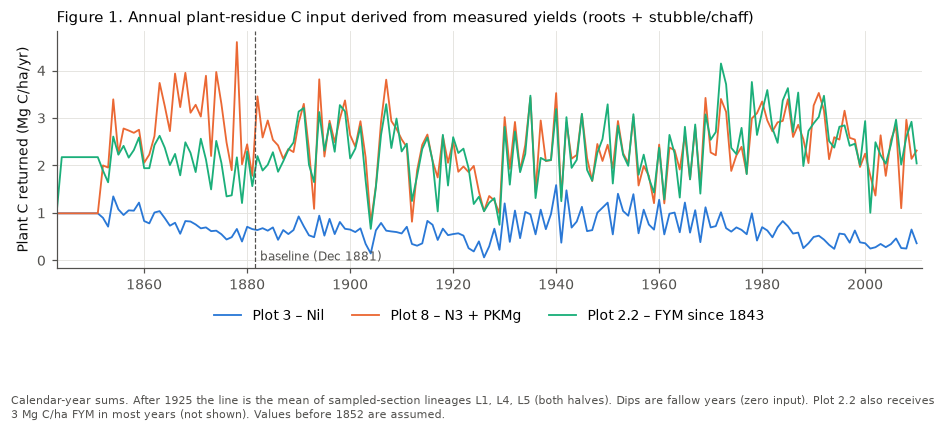

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
for p in PLOTS:
    a = ann[ann["plot"] == p]
    ax.plot(a.year, a.plant_c_Mg_ha, color=PLOT_COLOR[p], lw=1.2, label=PLOT_LABEL[p])
ax.axvline(BASELINE_YEAR + 0.5, color=INK2, lw=0.8, ls="--")
ax.text(BASELINE_YEAR + 1.5, 0.02, "baseline (Dec 1881)", color=INK2, fontsize=8, va="bottom", transform=ax.get_xaxis_transform())
ax.set_ylabel("Plant C returned (Mg C/ha/yr)")
ax.set_xlim(1843, END_YEAR + 1)
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.12))
ax.set_title("Figure 1. Annual plant-residue C input derived from measured yields (roots + stubble/chaff)", loc="left")
fig.text(0.01, -0.2, "Calendar-year sums. After 1925 the line is the mean of sampled-section lineages L1, L4, L5 (both halves). "
         "Dips are fallow years (zero input). Plot 2.2 also receives 3 Mg C/ha FYM in most years (not shown). "
         "Values before 1852 are assumed.", fontsize=7.5, color=INK2, wrap=True)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "figures" / "fig1_plant_c_inputs.png", bbox_inches="tight")
plt.show()

## 4. Initialisation

### 4.1 RothC implementation
This is a plain-Python port of `RothC_Py.py` (Rothamsted-Models/RothC_Py, commit `bd90ce3c…`, 12 Mar 2025, Apache-2.0). It is RothC-26.3, the standard 1990 single-biomass version.
* **Rate constants:** DPM 10, RPM 0.3, BIO 0.66, HUM 0.02 yr⁻¹.
* **Temperature modifier:** 47.91 / (1 + e^(106.06/(T+18.27))).
* **Moisture modifier:** TSMD with maximum −(20 + 1.3 clay − 0.01 clay²) × depth/23. The bare-soil limit is 0.556 × max, and the modifier is 1 above 0.444 × max, falling linearly to 0.2.
* **Cover modifier:** 0.6 under crop, 1.0 bare.
* **Partitioning:** CO₂/(BIO+HUM) = 1.67 (1.85 + 1.60 e^(−0.0786 clay)), with BIO:HUM = 46:54.
* **Inputs:** plant C split DPM:RPM 1.44:1; FYM split 49/49/2 % to DPM/RPM/HUM.

The radiocarbon bookkeeping is left out because it does not affect C stocks. The port also returns monthly CO₂ so that mass balance can be checked.

In [13]:
K_DPM, K_RPM, K_BIO, K_HUM = 10.0, 0.3, 0.66, 0.02

def rmf_tmp(t):
    return 0.0 if t < -5.0 else 47.91 / (math.exp(106.06 / (t + 18.27)) + 1.0)

def rmf_moist(rain, pan, clay, depth, pc, swc):
    smd_max = -(20.0 + 1.3 * clay - 0.01 * clay * clay) * depth / 23.0
    smd_1bar, smd_bare = 0.444 * smd_max, 0.556 * smd_max
    df = rain - 0.75 * pan
    if pc == 1:
        swc = max(smd_max, min(0.0, swc + df))
    else:
        swc = max(min(smd_bare, swc), min(0.0, swc + df))
    b = 1.0 if swc > smd_1bar else 0.2 + 0.8 * (smd_max - swc) / (smd_max - smd_1bar)
    return b, swc

def rothc_step(pools, tmp, rain, pan, pc, c_inp, fym, dpm_rpm, swc, clay=CLAY, depth=DEPTH):
    # One monthly RothC step. pools = (DPM, RPM, BIO, HUM) in Mg C/ha. Returns new pools, swc, CO2-C, rate modifier.
    b, swc = rmf_moist(rain, pan, clay, depth, pc, swc)
    rate = rmf_tmp(tmp) * b * (0.6 if pc == 1 else 1.0)
    dpm, rpm, bio, hum = pools
    dpm1, rpm1 = dpm * math.exp(-rate * K_DPM / 12), rpm * math.exp(-rate * K_RPM / 12)
    bio1, hum1 = bio * math.exp(-rate * K_BIO / 12), hum * math.exp(-rate * K_HUM / 12)
    decomposed = (dpm - dpm1) + (rpm - rpm1) + (bio - bio1) + (hum - hum1)
    x = 1.67 * (1.85 + 1.60 * math.exp(-0.0786 * clay))
    co2 = decomposed * x / (x + 1.0)
    bio_new = bio1 + decomposed * 0.46 / (x + 1.0)
    hum_new = hum1 + decomposed * 0.54 / (x + 1.0) + 0.02 * fym
    dpm_new = dpm1 + dpm_rpm / (dpm_rpm + 1.0) * c_inp + 0.49 * fym
    rpm_new = rpm1 + 1.0 / (dpm_rpm + 1.0) * c_inp + 0.49 * fym
    return (dpm_new, rpm_new, bio_new, hum_new), swc, co2, rate

def run_rothc(pools, swc, drv, iom, mass_tol=1e-9):
    # Run over a driver table; check mass balance each month; return monthly output.
    out = []
    cols = ["tmp_C", "rain_mm", "open_pan_mm", "plant_cover", "plant_c_Mg_ha", "fym_c_Mg_ha", "dpm_rpm"]
    for (y, m), (t, r, e, pc, ci, fy, dr) in zip(zip(drv.year.values, drv.month.values), drv[cols].itertuples(index=False, name=None)):
        prev = sum(pools)
        pools, swc, co2, rate = rothc_step(pools, t, r, e, int(pc), ci, fy, dr, swc)
        assert min(pools) >= 0.0, "negative pool"
        bal = prev + ci + fy - co2 - sum(pools)
        assert abs(bal) < mass_tol, f"mass balance error {bal} at {y}-{m}"
        out.append((y, m, *pools, iom, sum(pools) + iom, co2, swc, rate, bal))
    return pd.DataFrame(out, columns=["year", "month", "DPM", "RPM", "BIO", "HUM", "IOM", "SOC", "CO2", "SWC", "rate_mod", "mass_balance_err"]), pools, swc

### 4.2 Cross-checks against the official implementation
1. **Official sample calculation.** The port is run on the official `RothC_input.dat`, using the official program's equilibrium loop (repeat the first 12 months until the annual change is ≤ 10⁻⁶) followed by 828 monthly steps. The result is compared with the official `month_results.csv`.
2. **Official functions on identical Broadbalk inputs.** The function definitions in the pinned `RothC_Py.py` are extracted with `ast`, without running its script part. They are then run side by side with the port on the plot-3 drivers for 1882–2010.
3. **Manual worked example.** The port is checked against the January 1852 Hoosfield step printed in the RothC description (§2.2, rate modifier 0.3561).

In [14]:
# (1) official example input -> compare with official month_results.csv
hdr = pd.read_csv(FILES["rothc_example_input"], skiprows=3, nrows=1, sep=r"\s+")
ex = pd.read_csv(FILES["rothc_example_input"], skiprows=6, sep=r"\s+")
ex.columns = ["year", "month", "modern", "tmp", "rain", "evap", "c_inp", "fym", "pc", "dpm_rpm"]
clay_e, depth_e, iom_e, nsteps = float(hdr.clay[0]), float(hdr.depth[0]), float(hdr.iom[0]), int(hdr.nsteps[0])
pools, swc, k, toc1, test = (0.0, 0.0, 0.0, 0.0), 0.0, -1, 0.0, 100.0
while test > 1e-6:
    k = (k + 1) % 12
    r = ex.iloc[k]
    pools, swc, _, _ = rothc_step(pools, r.tmp, r.rain, r.evap, int(r.pc), r.c_inp, r.fym, r.dpm_rpm, swc, clay_e, depth_e)
    if (k + 1) % 12 == 0:
        toc0, toc1 = toc1, sum(pools)
        test = abs(toc1 - toc0)
port = []
for i in range(12, nsteps):
    r = ex.iloc[i]
    pools, swc, _, _ = rothc_step(pools, r.tmp, r.rain, r.evap, int(r.pc), r.c_inp, r.fym, r.dpm_rpm, swc, clay_e, depth_e)
    port.append((*pools, sum(pools) + iom_e))
port = pd.DataFrame(port, columns=["DPM", "RPM", "BIO", "HUM", "SOC"])
official = pd.read_csv(FILES["rothc_example_month_results"])
diff1 = {c: float((port[c].values - official[f"{c}_t_C_ha"].values).__abs__().max()) for c in ["DPM", "RPM", "BIO", "HUM", "SOC"]}
assert len(port) == len(official) == 828 and max(diff1.values()) < 1e-6, diff1
print("Check 1 - port vs official month_results.csv (828 months), max |diff| Mg C/ha:", {k: f"{v:.1e}" for k, v in diff1.items()})

# (3) manual worked example, Jan 1852 Hoosfield (rate modifier 0.3561 given; no inputs)
p0 = (0.1533, 4.4852, 0.6671, 25.8576)
dpm1, rpm1, bio1, hum1 = (p0[0]*math.exp(-10*0.3561/12), p0[1]*math.exp(-0.3*0.3561/12), p0[2]*math.exp(-0.66*0.3561/12), p0[3]*math.exp(-0.02*0.3561/12))
d = sum(p0) - (dpm1 + rpm1 + bio1 + hum1)
x = 1.67 * (1.85 + 1.60 * math.exp(-0.0786 * 23.4))
manual = dict(DPM=0.1140, RPM=4.4455, BIO=0.6651, HUM=25.8551)
got = dict(DPM=dpm1, RPM=rpm1, BIO=bio1 + d * 0.46 / (x + 1), HUM=hum1 + d * 0.54 / (x + 1))
assert all(abs(got[k] - manual[k]) < 1e-4 for k in manual), got
print("Check 3 - manual Jan-1852 example reproduced within 1e-4 (manual prints 4 d.p.):", {k: round(v, 4) for k, v in got.items()})

Check 1 - port vs official month_results.csv (828 months), max |diff| Mg C/ha: {'DPM': '2.2e-16', 'RPM': '2.7e-15', 'BIO': '4.8e-15', 'HUM': '1.1e-12', 'SOC': '1.1e-12'}
Check 3 - manual Jan-1852 example reproduced within 1e-4 (manual prints 4 d.p.): {'DPM': 0.1139, 'RPM': 4.4454, 'BIO': 0.6651, 'HUM': 25.8551}


In [15]:
# (2) official functions (extracted from the pinned file without executing its script section)
src_txt = FILES["rothc_py"].read_text(encoding="utf-8")
tree = ast.parse(src_txt)
func_src = "\n\n".join(ast.get_source_segment(src_txt, n) for n in tree.body if isinstance(n, ast.FunctionDef))
official_ns = {"np": np, "pd": pd, "IOM_Rage": [50000.0]}   # decomp() reads this script-level global
exec(compile(func_src, str(FILES["rothc_py"]), "exec"), official_ns)
assert {"RMF_Tmp", "RMF_Moist", "RMF_PC", "decomp", "RothC"} <= set(official_ns)

def run_official(pools0, swc0, drv, iom):
    DPM, RPM, BIO, HUM = ([v] for v in pools0)
    IOM, SOC, SWC = [iom], [0.0], [swc0]
    ages = [[0.0] for _ in range(5)]
    out = []
    with warnings.catch_warnings(), np.errstate(all="ignore"):
        warnings.simplefilter("ignore")
        for r in drv.itertuples(index=False):
            official_ns["RothC"](12, DPM, RPM, BIO, HUM, IOM, SOC, *ages, 1.0, CLAY, DEPTH, r.tmp_C, r.rain_mm,
                                 r.open_pan_mm, int(r.plant_cover), r.dpm_rpm, r.plant_c_Mg_ha, r.fym_c_Mg_ha, SWC)
            out.append(float(np.asarray(SOC[0]).ravel()[0]))
    return np.array(out)

_test_drv = DRIVERS[(DRIVERS["plot"] == "3") & (DRIVERS.unit == "L4H1")]
_p0 = (0.10, 3.0, 0.6, 21.0)
off = run_official(_p0, 0.0, _test_drv, 2.0)
mine, _, _ = run_rothc(_p0, 0.0, _test_drv, 2.0)
diff2 = float(np.abs(off - mine.SOC.values).max())
assert diff2 < 1e-9, diff2
print(f"Check 2 - official functions vs port on plot-3 drivers 1882-2010 ({len(off)} months): max |diff| = {diff2:.1e} Mg C/ha")
CROSSCHECK = pd.DataFrame([
    dict(check="port vs official month_results.csv (example input)", months=828, tolerance=1e-6, max_abs_diff=max(diff1.values())),
    dict(check="port vs official functions, Broadbalk plot 3 drivers", months=len(off), tolerance=1e-9, max_abs_diff=diff2),
    dict(check="port vs manual Jan-1852 worked example (printed to 4 d.p.)", months=1, tolerance=1e-4,
         max_abs_diff=max(abs(got[k] - manual[k]) for k in manual)),
])
CROSSCHECK.to_csv(OUTPUT_ROOT / "rothc_crosschecks.csv", index=False)
CROSSCHECK

Check 2 - official functions vs port on plot-3 drivers 1882-2010 (1548 months): max |diff| = 7.5e-14 Mg C/ha


,check,months,tolerance,max_abs_diff
0,port vs official month_results.csv (example in...,828,1.000000e-06,1.094236e-12
1,"port vs official functions, Broadbalk plot 3 d...",1548,1.000000e-09,7.460699e-14
2,port vs manual Jan-1852 worked example (printe...,1,1.000000e-04,6.287218e-05


### 4.3 Spin-up, treatment history to 1881, IOM and baseline scaling
* **Pre-1843 (assumed):** arable land in equilibrium under the climatology year. Each year it carries a winter-wheat-pattern crop at the plot-3 1852–1861 mean yield (unfertilised level), with no FYM. The equilibrium is the fixed point of the annual affine map x → A x + b, which is exact because RothC is linear in its pools once weather and cover are fixed. It is confirmed by brute-force iteration. The moisture deficit is spun up to its periodic state.
* **1843–1881 (known history):** each plot runs from that common state with its own recorded management and yields: FYM on 2.2, N3PK on 8 from 1852, half-strip straw return on 8 in 1866–1878, and assumed yields for 1844–1851. Weather is observed where available.
* **IOM:** Falloon et al. (1998), IOM = 0.049 × SOC^1.139 (both in Mg C/ha), applied to each plot's measured 1881 stock.
* **Scaling:** once, at the end of December 1881, the four active pools are multiplied by (SOC₁₈₈₁ − IOM) / Σactive. This keeps their proportions, the inferred split of the measured total. The scale factor *k* is reported as a diagnostic. It is not tuned.

In [16]:
def falloon_iom(soc):
    return 0.049 * soc ** 1.139

def equilibrium(drv_year, iom=0.0):
    # Exact steady state of a repeating 12-month driver table (pools 0-3). Also returns periodic SWC.
    swc = 0.0
    for _ in range(50):                       # periodic moisture state
        s0 = swc
        for r in drv_year.itertuples(index=False):
            _, swc = rmf_moist(r.rain_mm, r.open_pan_mm, CLAY, DEPTH, int(r.plant_cover), swc)
        if abs(swc - s0) < 1e-12:
            break
    def year_map(p, with_inputs):
        s = swc
        for r in drv_year.itertuples(index=False):
            ci, fy = (r.plant_c_Mg_ha, r.fym_c_Mg_ha) if with_inputs else (0.0, 0.0)
            p, s, _, _ = rothc_step(p, r.tmp_C, r.rain_mm, r.open_pan_mm, int(r.plant_cover), ci, fy, r.dpm_rpm, s)
        return np.array(p)
    b = year_map((0.0, 0.0, 0.0, 0.0), True)
    A = np.column_stack([year_map(tuple(np.eye(4)[j]), False) for j in range(4)])
    x = np.linalg.solve(np.eye(4) - A, b)
    return tuple(float(v) for v in x), swc

def climatology_year(plot, P, yields=None, fym=0.0):
    w = weather_table(1843, 1843, mode="climatology")
    g, s = (PRE_YIELD.grain, PRE_YIELD.straw) if yields is None else yields
    root, stub = plant_c(g, s, 1843, P)
    c = np.zeros(12); c[[3, 4, 5, 6]] = np.array(P["root_weights"]) * root; c[7] += stub
    f = np.zeros(12)
    if fym: f[9] = fym
    pc = np.array([1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1])     # sown 15 Oct, harvested 15 Aug (majority rule)
    assert [m for y, m in covered_months(pd.Timestamp(1842, 10, 15), pd.Timestamp(1843, 8, 15)) if y == 1843] == [1, 2, 3, 4, 5, 6, 7]
    return w.assign(plot=plot, plant_c_Mg_ha=c, fym_c_Mg_ha=f, plant_cover=pc, dpm_rpm=P["dpm_rpm"])

def initialise(D, P, mode="history"):
    # Return baseline states per plot plus a diagnostics table and the pre-baseline trajectories.
    states, diag, traj = {}, [], {}
    for p in PLOTS:
        iom = falloon_iom(BASELINE_STOCK[p])
        if mode == "history":
            pools0, swc0 = equilibrium(climatology_year(p, P))
            hist = D[(D["plot"] == p) & (D.unit == "strip")]
            assert hist.iloc[0][["year", "month"]].tolist() == [1843, 1] and hist.iloc[-1][["year", "month"]].tolist() == [BASELINE_YEAR, 12]
            out, pools, swc = run_rothc(pools0, swc0, hist, iom)
            traj[p] = out
        elif mode == "equilibrium":      # plot-specific equilibrium approximation (labelled scenario)
            s = strip[p][strip[p].harvest_year.between(1852, 1880)]
            fym_c = (s.fym_t.mean() / 35.0) * P["fym_c_per_35t"]
            pools0, swc0 = equilibrium(climatology_year(p, P, (s.grain.mean(), s.straw.mean()), fym_c))
            pools, swc = pools0, swc0
        active = sum(pools)
        k = (BASELINE_STOCK[p] - iom) / active
        assert k > 0
        scaled = tuple(v * k for v in pools)
        assert abs(sum(scaled) + iom - BASELINE_STOCK[p]) < 1e-9
        states[p] = dict(pools=scaled, swc=swc, iom=iom)
        diag.append(dict(plot=p, mode=mode, pre1843_active_equilibrium=sum(pools0), unscaled_active_Dec1881=active,
                         IOM=iom, scale_factor_k=k, SWC_Dec1881_mm=swc,
                         **{f"{n}_frac": v / sum(scaled) for n, v in zip(["DPM", "RPM", "BIO", "HUM"], scaled)},
                         baseline_total=sum(scaled) + iom))
    return states, pd.DataFrame(diag), traj

# Brute-force confirmation of the analytic equilibrium for the pre-1843 year
cy = climatology_year("3", BASE_PARAMS)
x_eq, swc_eq = equilibrium(cy)
p, s, years, prev = (0.0, 0.0, 0.0, 0.0), swc_eq, 0, -1.0
while True:
    for r in cy.itertuples(index=False):
        p, s, _, _ = rothc_step(p, r.tmp_C, r.rain_mm, r.open_pan_mm, int(r.plant_cover), r.plant_c_Mg_ha, r.fym_c_Mg_ha, r.dpm_rpm, s)
    years += 1
    if abs(sum(p) - prev) < 1e-6:
        break
    prev = sum(p)
print(f"Equilibrium (pre-1843 year): analytic active C = {sum(x_eq):.4f}; iterative ({years} yr, annual change < 1e-6) = {sum(p):.4f}; "
      f"|diff| = {abs(sum(x_eq) - sum(p)):.1e}. Periodic December SWC = {swc_eq:.2f} mm")
assert abs(sum(x_eq) - sum(p)) < 1e-3

STATES, INIT_DIAG, HIST = initialise(DRIVERS, BASE_PARAMS, "history")
INIT_DIAG.to_csv(OUTPUT_ROOT / "initialisation_primary.csv", index=False)
INIT_DIAG.round(4)

Equilibrium (pre-1843 year): analytic active C = 20.6575; iterative (1531 yr, annual change < 1e-6) = 20.6573; |diff| = 1.3e-04. Periodic December SWC = 0.00 mm


,plot,mode,pre1843_active_equilibrium,unscaled_active_Dec1881,IOM,scale_factor_k,SWC_Dec1881_mm,DPM_frac,RPM_frac,BIO_frac,HUM_frac,baseline_total
0,3,history,20.6575,17.4794,2.0727,1.4137,0.0,0.0006,0.0829,0.0142,0.9023,26.784
1,8,history,20.6575,29.7701,2.7447,1.0590,0.0,0.0009,0.2133,0.0306,0.7552,34.272
2,2.2,history,20.6575,50.2163,4.5134,0.9663,0.0,0.0164,0.2642,0.0313,0.6880,53.038


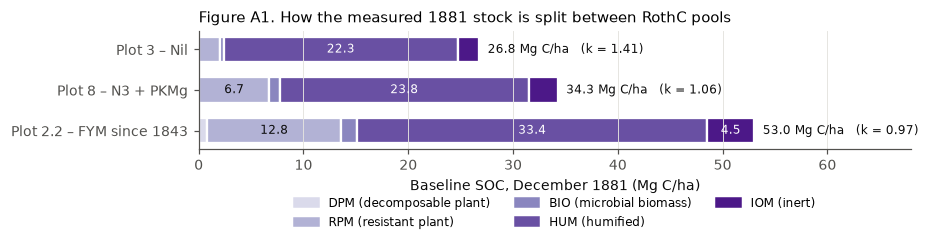

Caption: bar length is the measured 1881 stock. The split is inferred, not measured: it comes from the 1843-1881 history run after one rescaling of the active pools (factor k). IOM is from Falloon et al. (1998). The nil plot needed the largest k, meaning its yield-derived inputs supported the least SOC relative to what was measured.


In [17]:
# ---- Figure A1. Inferred pool partition of the measured 1881 stock
POOLS = ["DPM", "RPM", "BIO", "HUM", "IOM"]
POOL_NAME = {"DPM": "DPM (decomposable plant)", "RPM": "RPM (resistant plant)", "BIO": "BIO (microbial biomass)",
             "HUM": "HUM (humified)", "IOM": "IOM (inert)"}
POOL_COLOR = dict(zip(POOLS, plt.get_cmap("Purples")(np.linspace(0.25, 0.92, 5))))   # light = fast turnover, dark = inert
fig, ax = plt.subplots(figsize=(8.5, 2.6))
for y, p in enumerate(reversed(PLOTS)):
    vals = dict(zip(POOLS[:4], STATES[p]["pools"])); vals["IOM"] = STATES[p]["iom"]
    left = 0.0
    for pool in POOLS:
        w = vals[pool]
        ax.barh(y, w, left=left, height=0.62, color=POOL_COLOR[pool], edgecolor="white", linewidth=1.5)
        if w > 3.5:
            dark = pool in ("HUM", "IOM")
            ax.text(left + w / 2, y, f"{w:.1f}", ha="center", va="center", fontsize=8, color="white" if dark else INK)
        left += w
    k = INIT_DIAG.set_index("plot").loc[p, "scale_factor_k"]
    ax.text(left + 0.8, y, f"{left:.1f} Mg C/ha   (k = {k:.2f})", va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(PLOTS)))
ax.set_yticklabels([PLOT_LABEL[p] for p in reversed(PLOTS)])
ax.set_xlim(0, 68)
ax.set_xlabel("Baseline SOC, December 1881 (Mg C/ha)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=POOL_COLOR[q]) for q in POOLS], labels=[POOL_NAME[q] for q in POOLS],
          loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=8)
ax.set_title("Figure A1. How the measured 1881 stock is split between RothC pools", loc="left")
fig.tight_layout()
save_figure(fig, "figA1_baseline_pools.png")
plt.show()
caption("bar length is the measured 1881 stock. The split is inferred, not measured: it comes from the 1843-1881 history run "
        "after one rescaling of the active pools (factor k). IOM is from Falloon et al. (1998). The nil plot needed the largest k, "
        "meaning its yield-derived inputs supported the least SOC relative to what was measured.")

## 5. Scenarios
The **primary run** uses the settings above, including the predeclared 10 % stubble/chaff assumption. All were fixed before scoring and without reference to the holdout values. Five sensitivity scenarios were also declared before scoring. Each changes one assumption and is re-initialised the same way. **None is used to choose the primary run.** Their holdout scores are shown in §6 only to show how much each assumption matters.

| scenario | change |
|---|---|
| `equilibrium_init` | plot-specific equilibrium at the 1852–1880 mean inputs instead of propagated 1843–1881 history |
| `no_stubble` | *f*ₛ = 0 |
| `high_stubble` | *f*ₛ = 0.25 |
| `rhizodeposition` | root C × 1.65 (extra-root C factor 0.65 of Bolinder et al. 2007, as reported by Fujisaki et al. 2026) |
| `climatology_weather` | Table 7 climatology in every month (no observed weather) |

Each holdout prediction is the end-of-December simulated stock, averaged over the units that match the sample's footnote (sections 1, 6, 9 for 2000–2010). All predictions for all scenarios are written to disk and hashed **before** the sealed holdout values are reloaded.

In [18]:
SCENARIOS = {
    "primary": dict(params={}, init="history", weather="observed"),
    "equilibrium_init": dict(params={}, init="equilibrium", weather="observed"),
    "no_stubble": dict(params={"f_stub": 0.0}, init="history", weather="observed"),
    "high_stubble": dict(params={"f_stub": 0.25}, init="history", weather="observed"),
    "rhizodeposition": dict(params={"rhizo": 0.65}, init="history", weather="observed"),
    "climatology_weather": dict(params={}, init="history", weather="climatology"),
}
UNITS_FOR = {"all": list(UNIT_LINEAGE), "169": [u for u in UNIT_LINEAGE if UNIT_LINEAGE[u] in ("L1", "L4", "L5")],
             "19": [u for u in UNIT_LINEAGE if UNIT_LINEAGE[u] in ("L1", "L5")]}
PARAM_FINGERPRINT = hashlib.sha256(json.dumps({"base": BASE_PARAMS, "scen": SCENARIOS, "clay": CLAY, "depth": DEPTH},
                                              sort_keys=True, default=str).encode()).hexdigest()

def run_scenario(name):
    cfg = SCENARIOS[name]
    P = {**BASE_PARAMS, **cfg["params"]}
    if name == "primary":
        D = DRIVERS
    else:
        D = build_all_drivers(P, WEATHER if cfg["weather"] == "observed" else weather_table(1843, END_YEAR, "climatology"))
        check_drivers(D, P)
    states, diag, hist = initialise(D, P, cfg["init"])
    runs = []
    for p in PLOTS:
        for u in UNIT_LINEAGE:
            d = D[(D["plot"] == p) & (D.unit == u)]
            out, _, _ = run_rothc(states[p]["pools"], states[p]["swc"], d, states[p]["iom"])
            runs.append(out.assign(plot=p, unit=u))
    R = pd.concat(runs, ignore_index=True)
    return R, diag, hist

def sampled_mean(R, year, plot, sset, month=12):
    units = UNITS_FOR[sset]
    v = R[(R["plot"] == plot) & (R.year == year) & (R.month == month) & R.unit.isin(units)]
    assert len(v) == len(units), (year, plot, sset, len(v))
    return float(v.SOC.mean())

RESULTS, DIAGS = {}, {}
for name in SCENARIOS:
    RESULTS[name], DIAGS[name], _ = run_scenario(name)
    print(f"{name:20s} months simulated: {len(RESULTS[name]):,}  max |mass-balance error| = {RESULTS[name].mass_balance_err.abs().max():.1e}")
R0 = RESULTS["primary"]
assert (R0.IOM.groupby(R0["plot"]).nunique() == 1).all(), "IOM must stay constant"
assert (R0[["DPM", "RPM", "BIO", "HUM"]] >= 0).all().all()
first = R0[(R0.year == BASELINE_YEAR + 1) & (R0.month == 1)]
assert first.unit.nunique() == 10 and first.groupby("plot").size().eq(10).all()   # continuity from Dec 1881

primary              months simulated: 40,248  max |mass-balance error| = 2.8e-14


equilibrium_init     months simulated: 40,248  max |mass-balance error| = 2.8e-14


no_stubble           months simulated: 40,248  max |mass-balance error| = 2.8e-14


high_stubble         months simulated: 40,248  max |mass-balance error| = 2.8e-14


rhizodeposition      months simulated: 40,248  max |mass-balance error| = 2.8e-14


climatology_weather  months simulated: 40,248  max |mass-balance error| = 2.8e-14


In [19]:
# ---- Freeze predictions (holdout keys only; no observed values in memory) ----
pred_rows = []
for name, R in RESULTS.items():
    for r in holdout_keys.itertuples(index=False):
        pred_rows.append(dict(scenario=name, year=r.year, plot=r.plot, sampled_sections=r.sampled_sections,
                              simulated_Mg_C_ha=sampled_mean(R, r.year, r.plot, r.sampled_sections),
                              persistence_Mg_C_ha=BASELINE_STOCK[r.plot]))
PRED = pd.DataFrame(pred_rows)
PRED_FILE = OUTPUT_ROOT / "predictions_frozen.csv"
PRED.to_csv(PRED_FILE, index=False, float_format="%.6f")
PRED_SHA = sha256(PRED_FILE)
FREEZE = dict(predictions_sha256=PRED_SHA, parameter_fingerprint=PARAM_FINGERPRINT, holdout_seal_sha256=HOLDOUT_SEAL_SHA,
              n_predictions=len(PRED), primary_n=int((PRED.scenario == "primary").sum()))
(OUTPUT_ROOT / "freeze_record.json").write_text(json.dumps(FREEZE, indent=2))
print(json.dumps(FREEZE, indent=2))
PRED[PRED.scenario == "primary"].pivot(index="year", columns="plot", values="simulated_Mg_C_ha")[PLOTS].round(2)

{
  "predictions_sha256": "23dc1fd354161cd7d7ab0c597ba60ad6458479a34df0e51850399c6b05d1aadd",
  "parameter_fingerprint": "da63091b4d8646261d6cf8745d3a81f14be40c1372983a2165814029253f018f",
  "holdout_seal_sha256": "486e46db1cd93df4c75fd4744ebfda6017000960f22b0c0cf12b6f35d1576372",
  "n_predictions": 54,
  "primary_n": 9
}


plot,3,8,2.2
year,,,
2000,16.86,40.25,85.24
2005,16.21,39.55,85.00
2010,15.80,39.18,83.17


## 6. Evaluation
The holdout values were separated from the workbook in §2.3 and have not been in memory since. They are reloaded from the sealed file only now, after its hash and the hash of the frozen predictions are checked. All scores use Mg C/ha. Residual = simulated − observed.

In [20]:
assert sha256(SEALED_FILE) == HOLDOUT_SEAL_SHA and sha256(PRED_FILE) == PRED_SHA
holdout_obs = pd.read_csv(SEALED_FILE, dtype={"plot": str})
assert len(holdout_obs) == 9 and sorted(holdout_obs.year.unique()) == list(HOLDOUT_YEARS) and set(holdout_obs["plot"]) == set(PLOTS)
CMP = PRED.merge(holdout_obs[["year", "plot", "soc_Mg_C_ha", "source_cell"]], on=["year", "plot"], validate="many_to_one")
CMP = CMP.rename(columns={"soc_Mg_C_ha": "observed_Mg_C_ha"})
CMP["residual_rothc"] = CMP.simulated_Mg_C_ha - CMP.observed_Mg_C_ha
CMP["residual_persistence"] = CMP.persistence_Mg_C_ha - CMP.observed_Mg_C_ha
CMP.to_csv(OUTPUT_ROOT / "holdout_comparison_all_scenarios.csv", index=False, float_format="%.6f")
prim = CMP[CMP.scenario == "primary"][["year", "plot", "source_cell", "observed_Mg_C_ha", "simulated_Mg_C_ha", "residual_rothc",
                                       "persistence_Mg_C_ha", "residual_persistence"]].sort_values(["plot", "year"])
prim.to_csv(OUTPUT_ROOT / "holdout_comparison_primary.csv", index=False, float_format="%.6f")

def scores(df, res):
    e = df[res]
    return pd.Series(dict(n=len(e), MAE=e.abs().mean(), RMSE=np.sqrt((e ** 2).mean()), bias=e.mean()))

def score_table(df):
    rows = []
    for model, res in [("RothC", "residual_rothc"), ("persistence (1881 stock)", "residual_persistence")]:
        for p in PLOTS:
            rows.append(dict(model=model, plot=p, **scores(df[df["plot"] == p], res)))
        rows.append(dict(model=model, plot="pooled (9)", **scores(df, res)))
    t = pd.DataFrame(rows)
    t["n"] = t.n.astype(int)
    return t

SCORES = score_table(prim)
SCORES.to_csv(OUTPUT_ROOT / "holdout_scores_primary.csv", index=False, float_format="%.4f")
assert SCORES[SCORES["plot"] == "pooled (9)"].n.eq(9).all()
display(prim.round(2))
display(SCORES.round(2))

# ---- Opening-table check: the "What we found" table must agree with the scores saved above
OPENING_TABLE_RMSE = {'3': [8.01, 2.51], '8': [8.62, 3.48], '2.2': [6.75, 24.93], 'pooled (9)': [7.83, 14.6]}   # inserted at build time from the same values as the opening table
saved = pd.read_csv(OUTPUT_ROOT / "holdout_scores_primary.csv", dtype={"plot": str})
compact = (saved.pivot(index="plot", columns="model", values="RMSE")
           .reindex(["3", "8", "2.2", "pooled (9)"])[["RothC", "persistence (1881 stock)"]].round(2))
compact.index = ["Nil (plot 3)", "Mineral fertiliser (plot 8)", "Farmyard manure (plot 2.2)", "All nine observations"]
compact.columns = ["RothC", "Carry-forward (1881 stock)"]
for key, label in zip(["3", "8", "2.2", "pooled (9)"], compact.index):
    assert np.allclose(compact.loc[label].values, OPENING_TABLE_RMSE[key], rtol=0, atol=1e-9), (key, tuple(compact.loc[label]), OPENING_TABLE_RMSE[key])
print("Opening table agrees with outputs/holdout_scores_primary.csv (holdout RMSE, Mg C/ha):")
compact

,year,plot,source_cell,observed_Mg_C_ha,simulated_Mg_C_ha,residual_rothc,persistence_Mg_C_ha,residual_persistence
2,2000,2.2,E46,76.43,85.24,8.81,53.04,-23.39
5,2005,2.2,E47,78.95,85.00,6.05,53.04,-25.91
8,2010,2.2,E48,78.44,83.17,4.73,53.04,-25.41
0,2000,3,B46,24.48,16.86,-7.62,26.78,2.30
3,2005,3,B47,23.90,16.21,-7.70,26.78,2.88
6,2010,3,B48,24.48,15.80,-8.68,26.78,2.30
1,2000,8,D46,33.12,40.25,7.13,34.27,1.15
4,2005,8,D47,30.24,39.55,9.31,34.27,4.03
7,2010,8,D48,29.95,39.18,9.23,34.27,4.32


,model,plot,n,MAE,RMSE,bias
0,RothC,3,3,8.00,8.01,-8.00
1,RothC,8,3,8.56,8.62,8.56
2,RothC,2.2,3,6.53,6.75,6.53
3,RothC,pooled (9),9,7.69,7.83,2.36
4,persistence (1881 stock),3,3,2.50,2.51,2.50
5,persistence (1881 stock),8,3,3.17,3.48,3.17
6,persistence (1881 stock),2.2,3,24.90,24.93,-24.90
7,persistence (1881 stock),pooled (9),9,10.19,14.60,-6.41


Opening table agrees with outputs/holdout_scores_primary.csv (holdout RMSE, Mg C/ha):


,RothC,Carry-forward (1881 stock)
Nil (plot 3),8.01,2.51
Mineral fertiliser (plot 8),8.62,3.48
Farmyard manure (plot 2.2),6.75,24.93
All nine observations,7.83,14.60


In [21]:
# ---- Reproducibility: rescore from the exported CSV; confirm no parameter change after scoring
re_df = pd.read_csv(OUTPUT_ROOT / "holdout_comparison_primary.csv", dtype={"plot": str})
re_sc = score_table(re_df)
assert np.allclose(re_sc[["MAE", "RMSE", "bias"]].values, SCORES[["MAE", "RMSE", "bias"]].values, atol=1e-5)
fp_now = hashlib.sha256(json.dumps({"base": BASE_PARAMS, "scen": SCENARIOS, "clay": CLAY, "depth": DEPTH},
                                   sort_keys=True, default=str).encode()).hexdigest()
assert fp_now == PARAM_FINGERPRINT, "parameters changed after predictions were frozen"
print("Metrics reproduced from exported CSV; parameter fingerprint unchanged since freezing:", fp_now[:16])

# ---- Pre-holdout comparison (descriptive only; never used for fitting)
pre = obs_dev[obs_dev.year > BASELINE_YEAR].copy()
pre["simulated_Mg_C_ha"] = [sampled_mean(R0, y, p, s) for y, p, s in zip(pre.year, pre["plot"], pre.sampled_sections)]
pre["residual"] = pre.simulated_Mg_C_ha - pre.soc_Mg_C_ha
pre[["year", "plot", "sampled_sections", "soc_Mg_C_ha", "simulated_Mg_C_ha", "residual", "method_note"]].to_csv(
    OUTPUT_ROOT / "pre_holdout_comparison_descriptive.csv", index=False, float_format="%.4f")
print("PRE-HOLDOUT (descriptive, 1893-1997): mean residual by plot (Mg C/ha):",
      pre.groupby("plot").residual.mean().reindex(PLOTS).round(2).to_dict())
pre.pivot(index="year", columns="plot", values="residual")[PLOTS].round(2)

Metrics reproduced from exported CSV; parameter fingerprint unchanged since freezing: da63091b4d864626
PRE-HOLDOUT (descriptive, 1893-1997): mean residual by plot (Mg C/ha): {'3': -4.23, '8': 6.79, '2.2': 5.06}


plot,3,8,2.2
year,,,
1893,2.45,4.12,2.66
1914,-1.88,3.87,-5.53
1936,-5.97,NaN,2.60
1944,-6.95,3.84,4.54
1966,-5.84,3.82,0.79
1987,-6.98,9.31,11.14
1992,-4.46,10.35,14.30
1997,-4.25,12.24,9.99


### 6.1 Key result: change in SOC since 1881 (Figure 2)
Figure 2 is the main result. Each panel shows simulated and measured SOC change since the December 1881 baseline. The zero line is the carry-forward benchmark. The nil and mineral panels show the plot-level errors summarised in the opening table: RothC predicts a steady loss on the nil plot and a gain on the mineral plot, but measured SOC on both stayed within a few Mg C/ha of its 1881 value. The manure panel shows the large gain that RothC tracks and carry-forward cannot.

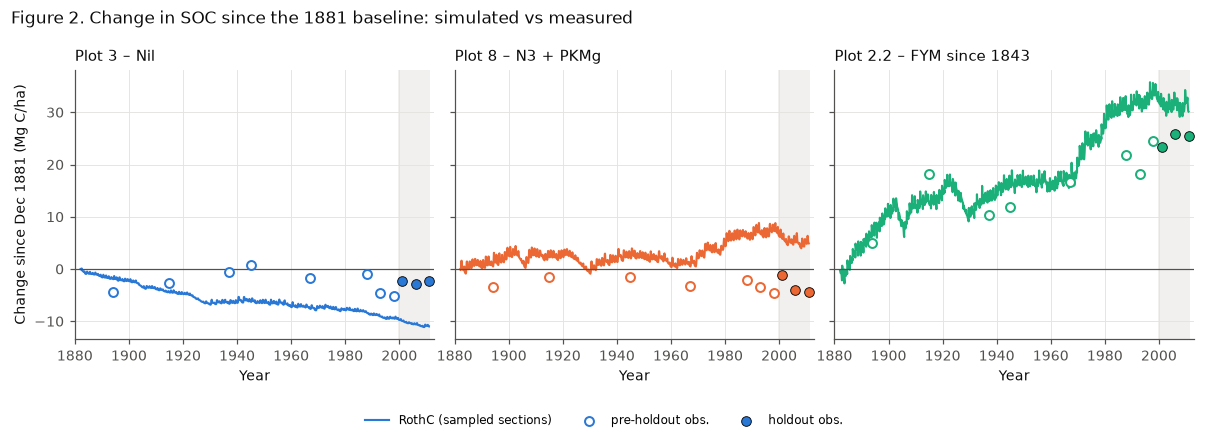

Caption: the y = 0 line is the carry-forward benchmark (1881 stock held constant). Matching the treatment ranking in absolute stocks (Figure 3) can reflect the different 1881 starting stocks alone; this figure shows whether the direction and size of change are reproduced. The shaded band is the holdout period (2000, 2005, 2010).


In [22]:
# ---- Monthly sampled-section series for figures (L1/L4/L5 mean; equals the strip mean before 1926)
def composite(R, units):
    return R[R.unit.isin(units)].groupby(["plot", "year", "month"]).SOC.mean().reset_index().assign(t=lambda d: d.year + (d.month - 0.5) / 12)
COMP = composite(R0, UNITS_FOR["169"])
COMP_ALL = composite(R0[R0.year <= 1967], UNITS_FOR["all"])
hist_df = pd.concat([HIST[p].assign(plot=p, t=lambda d: d.year + (d.month - 0.5) / 12) for p in PLOTS])
scale = INIT_DIAG.set_index("plot").scale_factor_k
hobs = holdout_obs.copy()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, p in zip(axes, PLOTS):
    c, b0 = PLOT_COLOR[p], BASELINE_STOCK[p]
    cc = COMP[COMP["plot"] == p]
    ax.plot(cc.t, cc.SOC - b0, color=c, lw=1.4, label="RothC (sampled sections)")
    ee = obs_dev[(obs_dev["plot"] == p) & (obs_dev.year > BASELINE_YEAR)]
    ax.scatter(ee.year + 1, ee.soc_Mg_C_ha - b0, marker="o", s=34, facecolor="white", edgecolor=c, lw=1.3, zorder=5, label="pre-holdout obs.")
    hh = hobs[hobs["plot"] == p]
    ax.scatter(hh.year + 1, hh.soc_Mg_C_ha - b0, marker="o", s=40, color=c, edgecolor=INK, lw=0.6, zorder=6, label="holdout obs.")
    ax.axhline(0, color=INK2, lw=0.8)
    ax.axvspan(1999.5, END_YEAR + 1.5, color=GRID, alpha=0.5, lw=0)
    ax.set_title(PLOT_LABEL[p], loc="left", color=INK)
    ax.set_xlim(1880, END_YEAR + 3)
    ax.set_xlabel("Year")
axes[0].set_ylabel("Change since Dec 1881 (Mg C/ha)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.1), fontsize=8)
fig.suptitle("Figure 2. Change in SOC since the 1881 baseline: simulated vs measured", x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "figures" / "fig2_change_since_1881.png", bbox_inches="tight")
plt.show()
print("Caption: the y = 0 line is the carry-forward benchmark (1881 stock held constant). Matching the treatment ranking in "
      "absolute stocks (Figure 3) can reflect the different 1881 starting stocks alone; this figure shows whether the "
      "direction and size of change are reproduced. The shaded band is the holdout period (2000, 2005, 2010).")

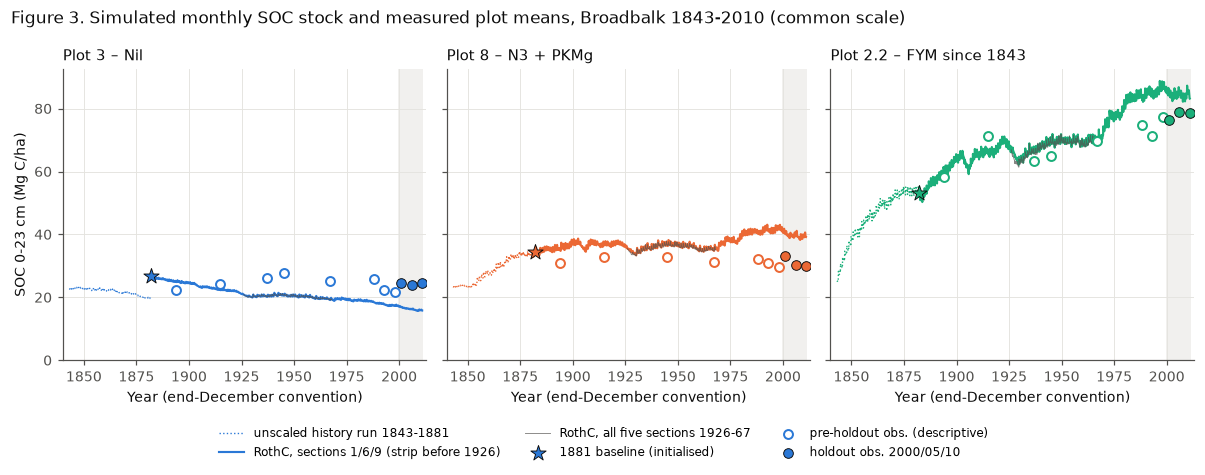

Caption: observations are placed at end-December of the sampling year. The dotted line is the 1843-1881 history run before the single baseline rescaling (factor k: 3 1.41, 8 1.06, 2.2 0.97). The shaded band is the holdout period. 1936/1944 means cover all five sections (grey line); 1966 and later cover sections 1, 6, 9 (1987: 1, 9).


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, p in zip(axes, PLOTS):
    c = PLOT_COLOR[p]
    h = hist_df[hist_df["plot"] == p]
    ax.plot(h.t, h.SOC, color=c, lw=0.9, ls=":", label="unscaled history run 1843-1881")
    cc = COMP[COMP["plot"] == p]
    ax.plot(cc.t, cc.SOC, color=c, lw=1.4, label="RothC, sections 1/6/9 (strip before 1926)")
    ca = COMP_ALL[(COMP_ALL["plot"] == p) & (COMP_ALL.year >= 1926)]
    ax.plot(ca.t, ca.SOC, color=INK2, lw=0.6, alpha=0.7, label="RothC, all five sections 1926-67")
    b = obs_dev[(obs_dev["plot"] == p)]
    bb, ee = b[b.year == BASELINE_YEAR], b[b.year > BASELINE_YEAR]
    ax.scatter(bb.year + 1, bb.soc_Mg_C_ha, marker="*", s=110, color=c, edgecolor=INK, lw=0.6, zorder=5, label="1881 baseline (initialised)")
    ax.scatter(ee.year + 1, ee.soc_Mg_C_ha, marker="o", s=34, facecolor="white", edgecolor=c, lw=1.3, zorder=5, label="pre-holdout obs. (descriptive)")
    hh = hobs[hobs["plot"] == p]
    ax.scatter(hh.year + 1, hh.soc_Mg_C_ha, marker="o", s=40, color=c, edgecolor=INK, lw=0.6, zorder=6, label="holdout obs. 2000/05/10")
    ax.axvspan(1999.5, END_YEAR + 1.5, color=GRID, alpha=0.5, lw=0)
    ax.set_title(PLOT_LABEL[p], loc="left", color=INK)
    ax.set_xlim(1840, END_YEAR + 3)
    ax.set_xlabel("Year (end-December convention)")
axes[0].set_ylabel("SOC 0-23 cm (Mg C/ha)")
axes[0].set_ylim(0, None)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.12), fontsize=8)
fig.suptitle("Figure 3. Simulated monthly SOC stock and measured plot means, Broadbalk 1843-2010 (common scale)", x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "figures" / "fig3_soc_stocks.png", bbox_inches="tight")
plt.show()
print("Caption: observations are placed at end-December of the sampling year. The dotted line is the 1843-1881 history run "
      "before the single baseline rescaling (factor k: " + ", ".join(f"{p} {scale[p]:.2f}" for p in PLOTS) + "). "
      "The shaded band is the holdout period. 1936/1944 means cover all five sections (grey line); 1966 and later cover sections 1, 6, 9 (1987: 1, 9).")

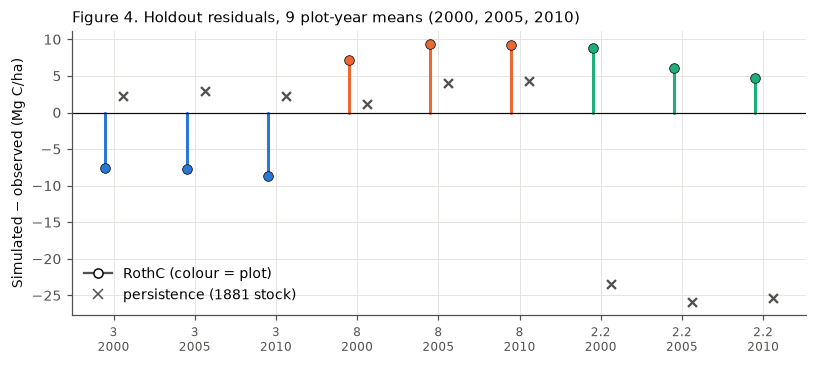

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
order = [(p, y) for p in PLOTS for y in HOLDOUT_YEARS]
xs = np.arange(len(order))
pm = prim.set_index(["plot", "year"])
for i, (p, y) in enumerate(order):
    r = pm.loc[(p, y)]
    ax.plot([i, i], [0, r.residual_rothc], color=PLOT_COLOR[p], lw=2, solid_capstyle="round")
    ax.scatter(i, r.residual_rothc, s=40, color=PLOT_COLOR[p], edgecolor=INK, lw=0.5, zorder=4)
    ax.scatter(i + 0.22, r.residual_persistence, s=34, marker="x", color=INK2, zorder=4)
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="-", color=INK2, markerfacecolor="white", markeredgecolor=INK, label="RothC (colour = plot)"),
           Line2D([], [], marker="x", ls="none", color=INK2, label="persistence (1881 stock)")]
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(xs + 0.1)
ax.set_xticklabels([f"{p}\n{y}" for p, y in order], fontsize=8)
ax.set_ylabel("Simulated − observed (Mg C/ha)")
ax.legend(handles=handles, loc="lower left")
ax.set_title("Figure 4. Holdout residuals, 9 plot-year means (2000, 2005, 2010)", loc="left")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "figures" / "fig4_holdout_residuals.png", bbox_inches="tight")
plt.show()

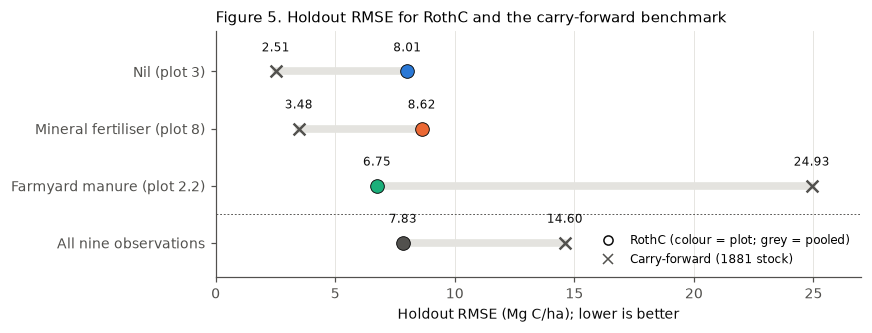

Caption: 2000, 2005 and 2010, three observations per plot. RothC wins on the pooled score only because carry-forward cannot follow the manure plot's gain. RothC’s RMSE was 3.2 times the carry-forward RMSE on the nil plot and 2.5 times on the mineral plot.


In [25]:
# ---- Figure 5. Holdout RMSE: RothC vs carry-forward (the opening table)
ROWS = [("3", "Nil (plot 3)"), ("8", "Mineral fertiliser (plot 8)"), ("2.2", "Farmyard manure (plot 2.2)"), ("pooled (9)", "All nine observations")]
sc = SCORES.pivot(index="plot", columns="model", values="RMSE")
fig, ax = plt.subplots(figsize=(8, 3.1))
for i, (key, label) in enumerate(ROWS):
    y = len(ROWS) - 1 - i
    rm, cf = sc.loc[key, "RothC"], sc.loc[key, "persistence (1881 stock)"]
    col = PLOT_COLOR.get(key, INK2)
    ax.plot([min(rm, cf), max(rm, cf)], [y, y], color=GRID, lw=5, solid_capstyle="round", zorder=1)
    ax.scatter(rm, y, s=80, color=col, edgecolor=INK, lw=0.6, zorder=3)
    ax.scatter(cf, y, s=60, marker="x", color=INK2, lw=1.6, zorder=3)
    for v in (rm, cf):
        ax.text(v, y + 0.3, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color=INK)
ax.axhline(0.5, color=INK2, lw=0.6, ls=(0, (2, 2)))
ax.set_yticks(range(len(ROWS)))
ax.set_yticklabels([lab for _, lab in reversed(ROWS)])
ax.set_ylim(-0.6, len(ROWS) - 0.3)
ax.set_xlim(0, 27)
ax.set_xlabel("Holdout RMSE (Mg C/ha); lower is better")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Line2D([], [], marker="o", ls="none", color=INK2, markerfacecolor="white", markeredgecolor=INK, label="RothC (colour = plot; grey = pooled)"),
                   Line2D([], [], marker="x", ls="none", color=INK2, label="Carry-forward (1881 stock)")],
          loc="lower right", fontsize=8)
ax.set_title("Figure 5. Holdout RMSE for RothC and the carry-forward benchmark", loc="left")
fig.tight_layout()
save_figure(fig, "fig5_holdout_rmse.png")
plt.show()
caption("2000, 2005 and 2010, three observations per plot. RothC wins on the pooled score only because carry-forward cannot "
        "follow the manure plot's gain. RothC’s RMSE was 3.2 times the carry-forward RMSE on the nil plot and 2.5 times on the mineral plot.")

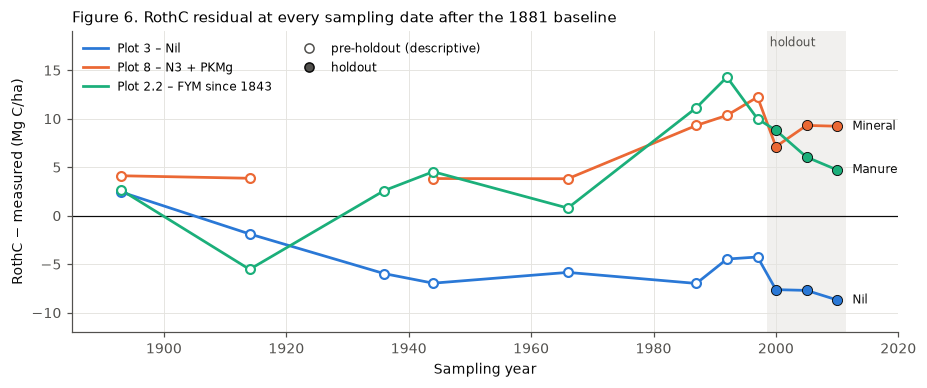

Caption: the opposite-sign errors on the nil and mineral plots build up from about 1914, long before the holdout period. Pre-holdout points were never used for fitting. Plot 8 has no 1936 measurement, so its line breaks there.


In [26]:
# ---- Figure 6. Residuals at every sampling date since 1881 (pre-holdout descriptive + holdout)
sampling_years = sorted(set(pre.year) | set(HOLDOUT_YEARS))
res_all = pd.concat([pre[["year", "plot", "residual"]].assign(kind="pre-holdout"),
                     prim[["year", "plot"]].assign(residual=prim.residual_rothc.values, kind="holdout")])
NICE = {"3": "Nil", "8": "Mineral", "2.2": "Manure"}
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.axvspan(1998.5, END_YEAR + 1.5, color=GRID, alpha=0.5, lw=0)
ax.axhline(0, color=INK, lw=0.8)
for p in PLOTS:
    d = res_all[res_all["plot"] == p].set_index("year").reindex(sampling_years)     # a missing date breaks the line
    c = PLOT_COLOR[p]
    ax.plot(d.index, d.residual, color=c, lw=1.8, label=PLOT_LABEL[p])
    pre_d, hol_d = d[d.kind == "pre-holdout"], d[d.kind == "holdout"]
    ax.scatter(pre_d.index, pre_d.residual, s=34, facecolor="white", edgecolor=c, lw=1.4, zorder=4)
    ax.scatter(hol_d.index, hol_d.residual, s=44, color=c, edgecolor=INK, lw=0.6, zorder=5)
    last = d.dropna(subset=["residual"]).iloc[-1]
    ax.text(END_YEAR + 2.5, last.residual, NICE[p], va="center", fontsize=8, color=INK)
ax.set_xlim(1885, END_YEAR + 10)
ax.set_ylim(-12, 19)
ax.text(1999, 18.5, "holdout", va="top", fontsize=8, color=INK2)
ax.set_xlabel("Sampling year")
ax.set_ylabel("RothC − measured (Mg C/ha)")
handles, labels = ax.get_legend_handles_labels()
handles += [Line2D([], [], marker="o", ls="none", markerfacecolor="white", markeredgecolor=INK2, color=INK2, label="pre-holdout (descriptive)"),
            Line2D([], [], marker="o", ls="none", color=INK2, markeredgecolor=INK, label="holdout")]
ax.legend(handles=handles, loc="upper left", ncol=2, fontsize=8)
ax.set_title("Figure 6. RothC residual at every sampling date after the 1881 baseline", loc="left")
fig.tight_layout()
save_figure(fig, "fig6_residuals_all_dates.png")
plt.show()
caption("the opposite-sign errors on the nil and mineral plots build up from about 1914, long before the holdout period. "
        "Pre-holdout points were never used for fitting. Plot 8 has no 1936 measurement, so its line breaks there.")

### 6.2 Changes and treatment gaps
Comparisons on the holdout dates, with 2010 as the final date. All values are in Mg C/ha.

In [27]:
def obs_at(y, p):
    s = hobs[(hobs.year == y) & (hobs["plot"] == p)]
    return float(s.soc_Mg_C_ha.iloc[0])
def sim_at(y, p, name="primary"):
    return float(PRED[(PRED.scenario == name) & (PRED.year == y) & (PRED["plot"] == p)].simulated_Mg_C_ha.iloc[0])
rows = []
for p in PLOTS:
    o, s = obs_at(END_YEAR, p) - BASELINE_STOCK[p], sim_at(END_YEAR, p) - BASELINE_STOCK[p]
    rows.append(dict(quantity=f"change 1881->2010, plot {p}", observed=o, simulated=s, same_sign=np.sign(o) == np.sign(s)))
for p, lab in [("8", "mineral - nil"), ("2.2", "FYM - nil")]:
    g0 = BASELINE_STOCK[p] - BASELINE_STOCK["3"]
    for y in HOLDOUT_YEARS:
        o = obs_at(y, p) - obs_at(y, "3") - g0
        s = sim_at(y, p) - sim_at(y, "3") - g0
        rows.append(dict(quantity=f"change in {lab} gap since 1881, {y}", observed=o, simulated=s, same_sign=np.sign(o) == np.sign(s)))
CHG = pd.DataFrame(rows)
CHG.to_csv(OUTPUT_ROOT / "change_and_gap_comparison.csv", index=False, float_format="%.4f")
# Opening-text check: mineral-plot change 1881->2010 quoted in "What we found"
_m = CHG.set_index("quantity").loc["change 1881->2010, plot 8"]
assert (round(_m.observed, 1), round(_m.simulated, 1)) == (-4.3, 4.9), (_m.observed, _m.simulated)
CHG.round(2)

,quantity,observed,simulated,same_sign
0,"change 1881->2010, plot 3",-2.30,-10.98,True
1,"change 1881->2010, plot 8",-4.32,4.91,False
2,"change 1881->2010, plot 2.2",25.41,30.13,True
3,"change in mineral - nil gap since 1881, 2000",1.15,15.90,True
4,"change in mineral - nil gap since 1881, 2005",-1.15,15.86,False
5,"change in mineral - nil gap since 1881, 2010",-2.02,15.90,False
6,"change in FYM - nil gap since 1881, 2000",25.69,42.12,True
7,"change in FYM - nil gap since 1881, 2005",28.79,42.54,True
8,"change in FYM - nil gap since 1881, 2010",27.71,41.12,True


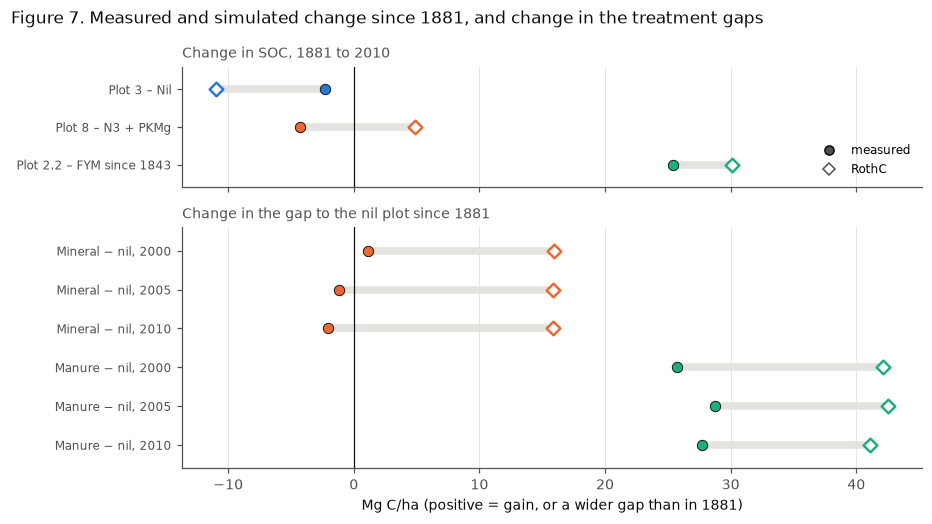

Caption: the grey bar between the two markers is RothC's error. Measured gaps between the mineral and nil plots barely moved, while RothC widens them by about 16 Mg C/ha; it also overstates the widening of the manure-nil gap.


In [28]:
# ---- Figure 7. Measured vs simulated change and treatment gaps
groups = [
    ("Change in SOC, 1881 to 2010", [(f"change 1881->2010, plot {p}", PLOT_LABEL[p], p) for p in PLOTS]),
    ("Change in the gap to the nil plot since 1881", [(f"change in {lab} gap since 1881, {y}", f"{name} − nil, {y}", p)
        for p, lab, name in [("8", "mineral - nil", "Mineral"), ("2.2", "FYM - nil", "Manure")] for y in HOLDOUT_YEARS]),
]
chg = CHG.set_index("quantity")
fig, axes = plt.subplots(2, 1, figsize=(8.5, 4.8), sharex=True, gridspec_kw={"height_ratios": [3, 6]})
for ax, (title, rows) in zip(axes, groups):
    for i, (q, label, p) in enumerate(rows):
        y = len(rows) - 1 - i
        o, s_ = chg.loc[q, "observed"], chg.loc[q, "simulated"]
        ax.plot([o, s_], [y, y], color=GRID, lw=5, solid_capstyle="round", zorder=1)
        ax.scatter(o, y, color=PLOT_COLOR[p], **MEASURED_KW)
        ax.scatter(s_, y, marker="D", s=40, facecolor="white", edgecolor=PLOT_COLOR[p], lw=1.6, zorder=4)
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([lab for _, lab, _ in reversed(rows)], fontsize=8)
    ax.set_ylim(-0.6, len(rows) - 0.4)
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=9, color=INK2)
axes[1].set_xlabel("Mg C/ha (positive = gain, or a wider gap than in 1881)")
axes[0].legend(handles=[Line2D([], [], marker="o", ls="none", color=INK2, markeredgecolor=INK, label="measured"),
                        Line2D([], [], marker="D", ls="none", markerfacecolor="white", markeredgecolor=INK2, label="RothC")],
               loc="lower right", fontsize=8)
fig.suptitle("Figure 7. Measured and simulated change since 1881, and change in the treatment gaps", x=0.01, ha="left", color=INK)
fig.tight_layout()
save_figure(fig, "fig7_change_and_gaps.png")
plt.show()
caption("the grey bar between the two markers is RothC's error. Measured gaps between the mineral and nil plots barely moved, "
        "while RothC widens them by about 16 Mg C/ha; it also overstates the widening of the manure-nil gap.")

### 6.3 Sensitivity scenarios (shown for information, not used for selection)
The primary run uses the predeclared 10 % stubble/chaff assumption. The other scenarios show how strongly the holdout errors depend on single input assumptions. They are not alternative candidates for the primary run.

In [29]:
sens = []
for name in SCENARIOS:
    d = CMP[CMP.scenario == name]
    s = scores(d, "residual_rothc")
    sens.append(dict(scenario=name, **s, **{f"bias_plot_{p}": d[d["plot"] == p].residual_rothc.mean() for p in PLOTS}))
SENS = pd.DataFrame(sens)
SENS["n"] = SENS.n.astype(int)
SENS = pd.concat([SENS, pd.DataFrame([dict(scenario="persistence benchmark", **scores(CMP[CMP.scenario == "primary"], "residual_persistence"),
        **{f"bias_plot_{p}": CMP[(CMP.scenario == "primary") & (CMP["plot"] == p)].residual_persistence.mean() for p in PLOTS})])], ignore_index=True)
SENS["n"] = SENS.n.astype(int)
SENS.to_csv(OUTPUT_ROOT / "holdout_scores_sensitivity.csv", index=False, float_format="%.4f")
display(pd.concat({n: d.set_index("plot")[["scale_factor_k", "HUM_frac", "RPM_frac"]] for n, d in DIAGS.items()}).unstack("plot").round(3))
SENS.round(2)

scale_factor_k               HUM_frac                \
plot                             3      8    2.2        3      8    2.2   
primary                      1.414  1.059  0.966    0.902  0.755  0.688   
equilibrium_init             1.482  0.611  0.418    0.828  0.828  0.816   
no_stubble                   1.783  1.304  1.082    0.903  0.750  0.674   
high_stubble                 1.079  0.826  0.833    0.902  0.760  0.704   
rhizodeposition              0.902  0.700  0.749    0.903  0.765  0.716   
climatology_weather          1.343  0.984  0.899    0.883  0.715  0.650   

                    RPM_frac                
plot                       3      8    2.2  
primary                0.083  0.213  0.264  
equilibrium_init       0.147  0.147  0.155  
no_stubble             0.082  0.218  0.276  
high_stubble           0.083  0.209  0.251  
rhizodeposition        0.083  0.205  0.242  
climatology_weather    0.099  0.247  0.297

,scenario,n,MAE,RMSE,bias,bias_plot_3,bias_plot_8,bias_plot_2.2
0,primary,9,7.69,7.83,2.36,-8.00,8.56,6.53
1,equilibrium_init,9,8.58,8.67,2.93,-8.47,9.14,8.12
2,no_stubble,9,4.42,5.79,-2.54,-9.60,2.11,-0.13
3,high_stubble,9,13.42,14.58,9.69,-5.60,18.21,16.46
4,rhizodeposition,9,17.50,20.04,14.96,-3.80,25.14,23.54
5,climatology_weather,9,10.25,10.56,5.61,-6.96,11.30,12.48
6,persistence benchmark,9,10.19,14.60,-6.41,2.50,3.17,-24.90


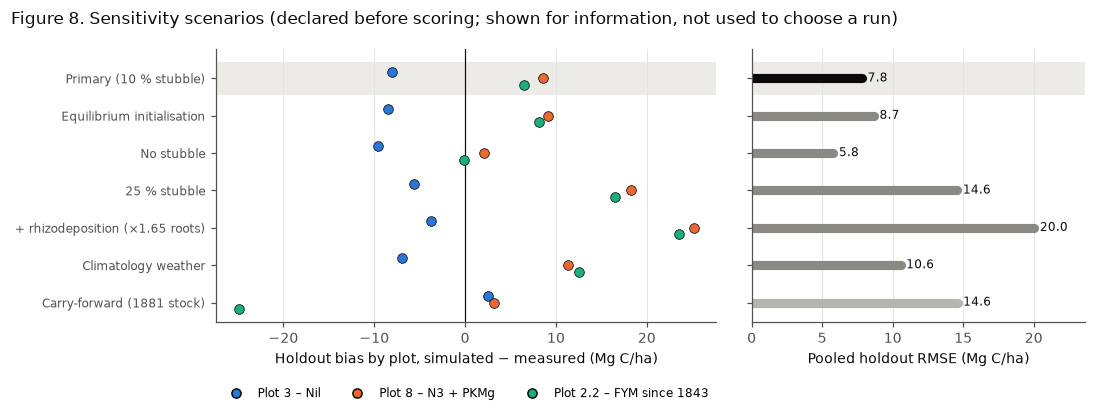

Caption: the shaded row is the primary run. Changing the assumed residue return moves every plot in the same direction, so no single input level removes the opposite-sign errors on the nil and mineral plots.


In [30]:
# ---- Figure 8. Sensitivity scenarios: per-plot bias and pooled RMSE (information only, not selection)
SCEN_LABEL = {"primary": "Primary (10 % stubble)", "equilibrium_init": "Equilibrium initialisation", "no_stubble": "No stubble",
              "high_stubble": "25 % stubble", "rhizodeposition": "+ rhizodeposition (×1.65 roots)",
              "climatology_weather": "Climatology weather", "persistence benchmark": "Carry-forward (1881 stock)"}
sens_plot = SENS.set_index("scenario").loc[list(SCEN_LABEL)]
yy = np.arange(len(sens_plot))[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
for y, (name, r) in zip(yy, sens_plot.iterrows()):
    if name == "primary":
        for a in (a1, a2):
            a.axhspan(y - 0.45, y + 0.45, color=GRID, alpha=0.7, lw=0)
    for j, p in enumerate(PLOTS):
        a1.scatter(r[f"bias_plot_{p}"], y + (1 - j) * 0.18, s=40, color=PLOT_COLOR[p], edgecolor=INK, lw=0.5, zorder=3)
    shade = INK if name == "primary" else ("#b5b4ae" if name == "persistence benchmark" else "#8a8984")
    a2.plot([0, r.RMSE], [y, y], color=shade, lw=6, solid_capstyle="round")
    a2.text(r.RMSE + 0.4, y, f"{r.RMSE:.1f}", va="center", fontsize=8, color=INK)
a1.axvline(0, color=INK, lw=0.8)
a1.set_yticks(yy)
a1.set_yticklabels([SCEN_LABEL[n] for n in sens_plot.index], fontsize=8)
a1.set_xlabel("Holdout bias by plot, simulated − measured (Mg C/ha)")
a1.legend(handles=[Line2D([], [], marker="o", ls="none", color=PLOT_COLOR[p], markeredgecolor=INK, label=PLOT_LABEL[p]) for p in PLOTS],
          loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)
a2.set_xlabel("Pooled holdout RMSE (Mg C/ha)")
a2.set_xlim(0, sens_plot.RMSE.max() * 1.18)
for a in (a1, a2):
    a.grid(axis="y", visible=False)
fig.suptitle("Figure 8. Sensitivity scenarios (declared before scoring; shown for information, not used to choose a run)",
             x=0.01, ha="left", color=INK)
fig.tight_layout()
save_figure(fig, "fig8_sensitivity.png")
plt.show()
caption("the shaded row is the primary run. Changing the assumed residue return moves every plot in the same direction, so "
        "no single input level removes the opposite-sign errors on the nil and mineral plots.")

In [31]:
# ---- Final verification summary
summary = dict(
    plots=len(PLOTS), layers=1, layer="0-23 cm", holdout_dates=list(HOLDOUT_YEARS), scored_observations=int(len(prim)),
    baseline_year=BASELINE_YEAR, baseline_stocks=BASELINE_STOCK,
    primary_pooled=SCORES[(SCORES.model == "RothC") & (SCORES["plot"] == "pooled (9)")][["MAE", "RMSE", "bias"]].round(3).iloc[0].to_dict(),
    persistence_pooled=SCORES[(SCORES.model != "RothC") & (SCORES["plot"] == "pooled (9)")][["MAE", "RMSE", "bias"]].round(3).iloc[0].to_dict(),
    rothc_crosscheck_max_abs_diff=float(CROSSCHECK.max_abs_diff.max()),
    max_mass_balance_error=float(max(R.mass_balance_err.abs().max() for R in RESULTS.values())),
    predictions_sha256=PRED_SHA, parameter_fingerprint=PARAM_FINGERPRINT, score_driven_parameter_changes=False,
    weather_months_observed_1882_2010={"temperature": int((WEATHER[WEATHER.year > 1881].tmp_source == "observed e-RA").sum()),
                                       "rain": int((WEATHER[WEATHER.year > 1881].rain_source == "observed e-RA").sum()),
                                       "evaporation": 0, "total": int((WEATHER.year > 1881).sum())},
    environment=dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__, matplotlib=matplotlib.__version__),
)
assert summary["plots"] == 3 and summary["layers"] == 1 and len(summary["holdout_dates"]) == 3 and summary["scored_observations"] == 9
(OUTPUT_ROOT / "run_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str))

{
  "plots": 3,
  "layers": 1,
  "layer": "0-23 cm",
  "holdout_dates": [
    2000,
    2005,
    2010
  ],
  "scored_observations": 9,
  "baseline_year": 1881,
  "baseline_stocks": {
    "3": 26.784,
    "8": 34.272,
    "2.2": 53.038
  },
  "primary_pooled": {
    "MAE": 7.695,
    "RMSE": 7.831,
    "bias": 2.363
  },
  "persistence_pooled": {
    "MAE": 10.189,
    "RMSE": 14.602,
    "bias": -6.413
  },
  "rothc_crosscheck_max_abs_diff": 6.287218319897536e-05,
  "max_mass_balance_error": 2.842170943040401e-14,
  "predictions_sha256": "23dc1fd354161cd7d7ab0c597ba60ad6458479a34df0e51850399c6b05d1aadd",
  "parameter_fingerprint": "da63091b4d8646261d6cf8745d3a81f14be40c1372983a2165814029253f018f",
  "score_driven_parameter_changes": false,
  "weather_months_observed_1882_2010": {
    "temperature": 1548,
    "rain": 1548,
    "evaporation": 0,
    "total": 1548
  },
  "environment": {
    "python": "3.11.9",
    "numpy": "2.4.6",
    "pandas": "3.1.1",
    "matplotlib": "3.11.2"
  }
}

## 7. Interpretation

**Headline (primary run, 9 holdout means, Mg C/ha).** Pooled over all nine, RothC has MAE 7.7, RMSE 7.8 and bias +2.4. The carry-forward benchmark (the 1881 stock held constant, also called persistence) has MAE 10.2, RMSE 14.6 and bias −6.4. The small pooled RothC bias hides errors of opposite sign by plot:

| plot | RothC bias | carry-forward bias |
|---|---|---|
| 3 nil | −8.0 | +2.5 |
| 8 N3PK | +8.6 | +3.2 |
| 2.2 FYM | +6.5 | −24.9 |

RothC beats carry-forward only on the FYM plot, so the pooled improvement comes from that plot. That is where SOC rose by ~25 Mg C/ha after 1881, and the model gets the direction and roughly the size of that rise. RothC’s RMSE was 3.2 times the carry-forward RMSE on the nil plot and 2.5 times on the mineral plot (2.51 vs 8.01 on nil, 3.48 vs 8.62 on mineral).

**Changes and gaps.**
* **Baseline to 2010:**
  * nil: observed −2.3, simulated −11.0 (right sign, about 5× too large);
  * mineral: observed −4.3, simulated +4.9 (**wrong sign**);
  * FYM: observed +25.4, simulated +30.1 (right sign, ~20 % too large).
* **Mineral − nil gap:** observed, it barely moved (−2.0 to +1.2 Mg C/ha across the holdout dates). Simulated, it widened by ~16.
* **FYM − nil gap:** observed, it widened by 26–29. Simulated, it widened by 41–43.

So the model reproduces the ranking, but mainly because the 1881 stocks already ranked the plots (Figure 3). It overstates how far the treatments diverge (Figure 2). The pre-holdout comparisons (descriptive only) show the same pattern growing from about 1914: the nil residuals are negative and the mineral residuals positive. The holdout result is therefore not caused by those three dates.

**A plausible explanation: excessive yield scaling (untested here).** Plant-C inputs were derived from yields with a fixed root:shoot ratio, so returned C scales with yield. Nil grain yields were 22–49 % of fertilised yields, depending on the era (22 % after 1968). The derived inputs are therefore about 0.5–0.9 versus 2.1–2.7 Mg C/ha/yr. The measured nil and N3PK stocks differ by only ~5–8 Mg C/ha after 130 years, which suggests below-ground and other unharvested inputs depend much less on yield than this allocation assumes. Candidates include:
* root and rhizodeposition C that responds weakly to fertiliser;
* weed biomass on unfertilised strips before herbicides arrived (1964);
* differences in harvest height or stubble.

The baseline scaling factors point the same way. They were fixed before evaluation and only reported as diagnostics. The 1843–1881 history run reached 17.5 Mg active C on the nil plot against 24.7 measured (*k* = 1.41), but 1.06 for N3PK and 0.97 for FYM. So even before scoring, these inputs already implied too little C for the nil plot relative to the others.

**Sensitivity (declared in advance, not used to select).** The primary run uses the predeclared assumption that stubble and chaff return 10 % of harvested dry matter. That fraction has no local source, and the sensitivity runs show how much the result depends on it. Setting it to zero lowers the pooled RMSE to 5.8; raising it to 25 % increases it to 14.6. Adding the Bolinder extra-root factor raises it to 20.0. The no-stubble run therefore measures sensitivity to assumed residue return; it is not evidence that no stubble was returned, and it is not adopted. Choosing it after seeing the holdout would amount to tuning on SOC.

No single input multiplier removes the opposite-sign plot errors. With no stubble the nil bias is still −9.6, and with more stubble the mineral and FYM biases grow. This is consistent with the excessive yield-scaling explanation above, which remains plausible but untested. Initialising from plot-specific equilibria instead of the known 1843–1881 history makes the scores slightly worse (RMSE 8.7). Using climatology instead of observed weather increases the bias (RMSE 10.6).

**What three holdout dates can support.**
* The nine means come from three plots at three dates spanning ten years. Within a plot they share sections, methods and one model trajectory, so they act more like three plot-level comparisons than nine independent tests. No confidence intervals are given.
* Measured means move by up to ~4 Mg C/ha between nearby sampling years. For example, the nil plot went from 25.9 (1987) to 22.2 (1992) to 21.6 (1997) to 24.5 (2000). Score differences of a few Mg C/ha between scenarios are within that noise.
* What the holdout does support is the sign and rough size of the plot-specific biases. They are large (6–9 Mg C/ha), consistent across all three dates, and already visible in the pre-holdout record.

**Sampling and analytical practice.**
* **Methods changed:** archived re-analyses up to 1944, Walkley-Black × 1.3 in 1966, Tinsley in 1987, and combustion minus carbonate from 1992. Calibration offsets between these methods could be comparable to the treatment signals on the nil and mineral plots.
* **Sampled area changed:** strip means up to 1944, then sections 1/6/9 (only 1/9 in 1987). The model follows these definitions section by section, but within-strip heterogeneity is not modelled.
* **FYM correction:** plot 2.2 stocks include a soil-mass/depth correction that the archive itself says is probably an underestimate. That could explain part of the positive FYM bias.
* **Constant soil weight:** nil and mineral stocks use a fixed soil weight (2.88 × 10⁶ kg/ha), so any change in bulk density is ignored.

**Residue and manure uncertainty.**
* **Straw gaps:** straw was not recorded on the sampled sections in 1980–1995 and 2004–2010. It was estimated from grain × the plot's straw:grain ratio. Of the holdout sampling years, 2005 and 2010 fall inside these gaps; 2000 does not. The 2000 prediction still depends on imputed straw: straw feeds the harvested dry matter from which stubble and root C are derived, and the C returned in 1980–1995 persists in the slower RPM and HUM pools for years to decades.
* **Stubble and chaff:** the fraction (10 %) is an assumption with no local source.
* **Root:shoot ratio:** the values (0.625 / 0.5325) come from Siddique et al. (1990), via Woolf & Lehmann, for wheat in a Mediterranean environment, and are applied unchanged to Broadbalk for 170 years.
* **Root depth and C fraction:** all root C is assumed to enter 0–23 cm, which is an upper bound. The straw C fraction is applied to roots and stubble.
* **FYM:** fixed at 3 Mg C per 35 t throughout, although its composition surely changed. The e-RA FYM composition dataset (DOI 10.23637/rbk1-FYM-01) was not used.
* **Early years:** yields for 1844–1851, plot 8's early treatments and pre-1843 management are assumed. They only affect the inferred pool proportions in 1881, because the active pools are rescaled once there.

**Climate and fallow approximations.**
* **Evaporation:** taken from the Table 7 climatology in every month. Temperature and rainfall are observed throughout the evaluated period (1882–2010).
* **Moisture variability:** using climatological open-pan evaporation means the model misses dry-year variability in the moisture modifier.
* **Fallows:** sequential fallows (1926–1967), the half-strip fallows of 1904/05 and the section-6 fallows of 1968–1977 are represented explicitly by section. FYM is assumed not to have gone on the fallowed half-strip in 1904/05.

**Scope.** This is a retrospective simulation with historical weather and yields, not a forecast. The results apply to RothC-26.3 with these input rules, at Broadbalk, for plots 3, 8 and 2.2, in the 0–23 cm layer. They do not show that RothC fails or succeeds elsewhere. Under SOC-independent, yield-proportional inputs, RothC captured the large manure-driven gain but not the near-stability of the unmanured and mineral-fertilised soils. The unresolved input gaps above, especially the treatment dependence of root and other unharvested C, need resolving before the model's structure can be judged.